# Air quality in Italy, from the week to the decade

In [1]:
from pathlib import Path
from io import StringIO
import calendar
import os
import warnings

PACKAGE = Path.cwd().resolve()
assert (PACKAGE / 'assets/fonts').exists(), 'Run the notebook from the repository root'
RAW = Path(os.environ.get('GRINS_RAW', PACKAGE / 'data/raw/zenodo'))
OUTPUT = PACKAGE / 'outputs/pollution_patterns'
TABLES = OUTPUT / 'tables'
CACHE = OUTPUT / 'cache'
IMAGES = OUTPUT / 'images'
for folder in (TABLES, CACHE, IMAGES):
    folder.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(OUTPUT / 'cache/matplotlib'))

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import TwoSlopeNorm, to_rgba, LinearSegmentedColormap
from matplotlib.patches import Polygon, Rectangle
from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea, VPacker
import numpy as np
import pandas as pd
from dateutil.easter import easter
from scipy import linalg, stats
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestCentroid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import Image as ShowImage, display

warnings.filterwarnings('ignore', message='Mean of empty slice')

files = sorted(RAW.glob('GRINS_AQCLIM_points_Italy_y*.csv'))
assert len(files) == 6 and (RAW / 'Station_registry_information.CSV').exists(), 'Original files not found: download them from Zenodo into data/raw/zenodo/'

## 1. Data and shared rules

In [2]:
CORE = ['NO2', 'PM10', 'PM2.5', 'O3']
ADDED = ['NO', 'CO', 'SO2']
POLLUTANTS = CORE + ADDED
YEARS = list(range(2013, 2024))
KEYS = ['AirQualityStation', 'year', 'pollutant']
SEED = 20261105
SEASONS = {'winter': [12, 1, 2], 'spring': [3, 4, 5],
           'summer': [6, 7, 8], 'autumn': [9, 10, 11]}
BLOCKS = {'early': [2013, 2014, 2015], 'late': [2021, 2022, 2023]}
RIPARTIZIONI = {1: 'North-West', 2: 'North-East', 3: 'Centre', 4: 'South', 5: 'Islands'}
REGIONS = {1: 'Piemonte', 2: "Valle d'Aosta", 3: 'Lombardia', 4: 'Trentino-Alto Adige',
           5: 'Veneto', 6: 'Friuli-Venezia Giulia', 7: 'Liguria', 8: 'Emilia-Romagna',
           9: 'Toscana', 10: 'Umbria', 11: 'Marche', 12: 'Lazio', 13: 'Abruzzo', 14: 'Molise',
           15: 'Campania', 16: 'Puglia', 17: 'Basilicata', 18: 'Calabria',
           19: 'Sicilia', 20: 'Sardegna'}


def save(frame, name):
    TABLES.mkdir(parents=True, exist_ok=True)
    frame.to_csv(TABLES / name, index=False)
    print(f'{name}: {len(frame):,} rows', flush=True)
    return frame


def read(name):
    return pd.read_csv(TABLES / name, float_precision='round_trip')


def three_areas(values):
    return np.where(np.isin(values, ['North-West', 'North-East']), 'North',
                    np.where(np.isin(values, ['South', 'Islands']), 'South and Islands', values))


def registry():
    frame = pd.read_csv(RAW / 'Station_registry_information.CSV')
    assert len(frame) == 744 and frame.AirQualityStation.is_unique
    station_type, area = frame.AirQualityStationType, frame.AirQualityStationArea
    frame['class'] = 'other'
    for code, kind, location in [('UT', 'traffic', 'urban'), ('UB', 'background', 'urban'),
                                  ('SB', 'background', 'suburban'), ('ST', 'traffic', 'suburban')]:
        frame.loc[station_type.eq(kind) & area.eq(location), 'class'] = code
    frame.loc[station_type.eq('background') & area.str.startswith('rural'), 'class'] = 'RB'
    frame.loc[station_type.eq('industrial'), 'class'] = 'IN'
    frame['ripartizione'] = frame.COD_RIP.map(RIPARTIZIONI)
    frame['region'] = frame.COD_REG.map(REGIONS)
    frame['area3'] = three_areas(frame.ripartizione)
    assert frame[['region', 'ripartizione']].notna().all().all()
    return frame


def raw_daily(use_cache=True):
    path = CACHE / 'daily.pkl'
    if use_cache and path.exists():
        return pd.read_pickle(path)
    files = sorted(RAW.glob('GRINS_AQCLIM_points_Italy_y*.csv'))
    assert len(files) == 6
    columns = ['AirQualityStation', 'time'] + ['AQ_mean_' + p for p in POLLUTANTS]
    frame = pd.concat([pd.read_csv(path, usecols=columns, parse_dates=['time'])
                       for path in files], ignore_index=True)
    assert len(frame) == 2988648
    assert not frame.duplicated(['AirQualityStation', 'time']).any()
    assert frame.groupby('AirQualityStation').size().eq(4017).all()
    assert set(frame.AirQualityStation) == set(registry().AirQualityStation)
    assert set(frame.time.unique()) == set(pd.date_range('2013-01-01', '2023-12-31'))
    frame = frame.rename(columns={'AQ_mean_' + p: p for p in POLLUTANTS})
    frame['year'] = frame.time.dt.year
    if use_cache:
        CACHE.mkdir(parents=True, exist_ok=True)
        frame.to_pickle(path)
    return frame


def station_year(daily):
    pieces = []
    keys = [daily.AirQualityStation, daily.year]
    quarter, warm = daily.time.dt.quarter, daily.time.dt.month.between(4, 9)
    for pollutant in POLLUTANTS:
        values = daily[pollutant]
        valid = values.notna() & np.isfinite(values)
        summary = values.where(valid).groupby(keys).agg(mean='mean', n_valid='count')
        expected = np.array([366 if calendar.isleap(y) else 365 for _, y in summary.index])
        summary['coverage'] = summary.n_valid / expected
        quarters = []
        for q in range(1, 5):
            count = (valid & quarter.eq(q)).groupby(keys).sum()
            denominator = [sum(calendar.monthrange(y, m)[1] for m in range(3*q-2, 3*q+1))
                           for _, y in summary.index]
            quarters.append(count / denominator)
        summary['minimum_quarter_coverage'] = pd.concat(quarters, axis=1).min(axis=1)
        summary['apr_sep_coverage'] = (valid & warm).groupby(keys).sum() / 183
        summary['oct_mar_coverage'] = (valid & ~warm).groupby(keys).sum() / (expected - 183)
        summary['eligible_main'] = summary.coverage.ge(.75) & summary.minimum_quarter_coverage.ge(.70)
        if pollutant == 'O3':
            summary['eligible_main'] &= summary.apr_sep_coverage.ge(.75) & summary.oct_mar_coverage.ge(.75)
        summary['pollutant'] = pollutant
        pieces.append(summary.reset_index())
    return pd.concat(pieces, ignore_index=True)


def floor_flags(daily, annual):
    pieces = []
    index = pd.MultiIndex.from_product([sorted(daily.AirQualityStation.unique()), YEARS],
                                      names=['AirQualityStation', 'year'])
    for pollutant in POLLUTANTS:
        frame = daily[['AirQualityStation', 'year', pollutant]].rename(columns={pollutant: 'value'})
        frame = frame[frame.value.notna() & np.isfinite(frame.value)]
        keys = ['AirQualityStation', 'year']
        summary = frame.groupby(keys).value.agg(p25=lambda x: x.quantile(.25))
        counts = frame.groupby(keys + ['value']).size().rename('modal_n').reset_index()
        modes = counts.sort_values(['modal_n', 'value'], ascending=[False, True]).drop_duplicates(keys)
        modes = modes.set_index(keys).rename(columns={'value': 'modal_value'})
        summary = summary.join(modes[['modal_value', 'modal_n']]).reindex(index).reset_index()
        summary['pollutant'] = pollutant
        pieces.append(summary)
    flags = pd.concat(pieces, ignore_index=True).merge(
        annual[KEYS + ['n_valid', 'coverage', 'minimum_quarter_coverage']], on=KEYS, validate='one_to_one')
    flags['modal_share'] = flags.modal_n / flags.n_valid.replace(0, np.nan)
    flags['eligible'] = flags.coverage.ge(.75) & flags.minimum_quarter_coverage.ge(.70)
    flags['flag'] = flags.eligible & flags.modal_share.gt(.2) & flags.modal_value.le(flags.p25)
    return flags[KEYS + ['n_valid', 'p25', 'modal_value', 'modal_n', 'modal_share', 'eligible', 'flag']]


def eligible_years(annual=None, flags=None):
    annual = read('common_annual.csv') if annual is None else annual
    flags = read('common_floors.csv') if flags is None else flags
    frame = annual.merge(flags[KEYS + ['flag']], on=KEYS, validate='one_to_one')
    frame['eligible'] = frame.eligible_main & ~(frame.pollutant.isin(ADDED) & frame.flag)
    return frame.loc[frame.eligible, KEYS]


def load_daily():
    daily = raw_daily().copy()
    eligible = eligible_years()
    for pollutant in POLLUTANTS:
        keys = eligible.loc[eligible.pollutant.eq(pollutant), ['AirQualityStation', 'year']]
        mask = pd.MultiIndex.from_frame(daily[['AirQualityStation', 'year']]).isin(pd.MultiIndex.from_frame(keys))
        daily.loc[~mask | daily[pollutant].le(0), pollutant] = np.nan
    return daily.dropna(subset=POLLUTANTS, how='all').reset_index(drop=True)


def monthly(daily=None, flags=None, eligible=False):
    daily = raw_daily() if daily is None else daily
    flags = read('common_floors.csv') if flags is None else flags
    pieces = []
    allowed = eligible_years() if eligible else None
    for pollutant in POLLUTANTS:
        frame = daily[['AirQualityStation', 'time', 'year', pollutant]].rename(columns={pollutant: 'value'})
        frame = frame[frame.value.notna() & frame.value.gt(0)].copy()
        if eligible:
            frame = frame.merge(allowed[allowed.pollutant.eq(pollutant)].drop(columns='pollutant'),
                                on=['AirQualityStation', 'year'], validate='many_to_one')
        else:
            rejected = flags[flags.pollutant.eq(pollutant) & flags.modal_share.gt(.2)
                             & flags.modal_value.le(flags.p25)]
            frame = frame.merge(rejected[['AirQualityStation', 'year']].assign(_floor=True),
                                how='left', on=['AirQualityStation', 'year'], validate='many_to_one')
            frame = frame[frame._floor.isna()]
        frame['month'] = frame.time.dt.month
        result = frame.groupby(['AirQualityStation', 'year', 'month']).value.agg(n_days='size', mean='mean').reset_index()
        result = result[result.n_days.ge(15)].copy()
        result['lm'] = np.log(result['mean'])
        result['pollutant'] = pollutant
        pieces.append(result)
    return pd.concat(pieces, ignore_index=True).sort_values(['pollutant', 'AirQualityStation', 'year', 'month']).reset_index(drop=True)


def bootstrap_median(values, rng):
    samples = np.median(rng.choice(values, size=(4000, len(values)), replace=True), axis=1)
    return np.percentile(samples, [2.5, 97.5])

In [3]:
daily = raw_daily()
annual = station_year(daily)
flags = floor_flags(daily, annual)
save(annual, 'common_annual.csv')
save(flags, 'common_floors.csv')
save(registry(), 'common_registry.csv')
save(monthly(daily, flags), 'common_monthly.csv')
del daily

common_annual.csv: 57,288 rows


common_floors.csv: 57,288 rows


common_registry.csv: 744 rows


common_monthly.csv: 267,239 rows


## Figure helpers

In [4]:
COLOURS = {'NO2': '#1D4F96', 'PM10': '#F08A2C', 'PM2.5': '#A84E1A',
           'O3': '#D6337A', 'SO2': '#8A63C9', 'CO': '#1A9C8F', 'NO': '#5DA9E9'}
NAMES = {'NO2': 'NO₂', 'PM10': 'PM10', 'PM2.5': 'PM2.5', 'O3': 'O₃', 'SO2': 'SO₂', 'CO': 'CO', 'NO': 'NO'}
INK, MUTED, GREY = '#1B2430', '#666666', '#E3E3E3'
TITLE, ACCENT = '#142D4F', '#245A81'
MIN_FONT = 14
for font_name in ('Inter-Regular.ttf', 'Inter-SemiBold.ttf'):
    font_manager.fontManager.addfont(PACKAGE / 'assets/fonts' / font_name)
plt.rcParams.update({'font.family': 'Inter', 'font.size': 15,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelcolor': INK, 'text.color': INK, 'axes.titleweight': 'semibold',
                     'axes.titlecolor': TITLE, 'xtick.color': INK, 'ytick.color': INK, 'axes.edgecolor': INK,
                     'mathtext.fontset': 'custom', 'mathtext.rm': 'Inter', 'mathtext.it': 'Inter',
                     'mathtext.bf': 'Inter:semibold', 'savefig.facecolor': 'none'})
ML_ORDER = ['NO2', 'NO', 'CO', 'PM10', 'PM2.5', 'O3', 'SO2']
AREAS = ['North-West', 'North-East', 'Centre', 'South', 'Islands']
BAND_COLOURS = {'winter-trap': '#3E5468', 'in between': '#C8C8C8', 'year-round': '#D9B36C'}
MEMBERSHIP_CMAP = LinearSegmentedColormap.from_list('membership', [BAND_COLOURS['year-round'], BAND_COLOURS['in between'], BAND_COLOURS['winter-trap']])
MISSED = '#B5520B'
PLACE_LIMITS = ((0.4, 3.5), (0.07, 1.4))
CLOCK_MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
PHASES_2020 = [('W0', 'Before', '01-01', '02-22'), ('W1', 'Red\nzones', '02-23', '03-09'), ('W2', 'National\nlockdown', '03-10', '05-03'), ('W3', 'Phase\n2', '05-04', '05-17'), ('W4', 'Reopening, summer', '05-18', '09-30'), ('W5', 'Autumn', '10-01', '11-05'), ('W6', 'Second wave\n(regional tiers)', '11-06', '12-31')]
PHASE_LEGEND = '2020, median of station changes'
SEASON_ORDER = ['spring', 'summer', 'autumn', 'winter']
HEATMAP_ORDER = ['NO2', 'CO', 'PM10', 'PM2.5', 'SO2', 'O3']


def fig_read(name):
    path = RAW / 'Station_registry_information.CSV' if name == 'registry' else TABLES / name
    return pd.read_csv(path, low_memory=False)


def frame():
    return plt.figure(figsize=(16, 9))


def save_figure(fig, name, slide, bbox=None):
    style_text(fig)
    fig.savefig(IMAGES / f'{name}.png', dpi=300, transparent=True, bbox_inches=bbox or 'tight', pad_inches=.12)
    plt.close(fig)
    print(f'{name}.png', flush=True)
    display(ShowImage(filename=str(IMAGES / f'{name}.png'), width=900))


def style_text(fig):
    from matplotlib.text import Text
    assert all(text is getattr(fig, '_supylabel', None) for text in fig.texts)
    enforce_min_font(fig)
    for label in fig.findobj(Text):
        label.set_fontfamily('Inter')
        if label.get_fontweight() in ('bold', 'semibold', 600, 700):
            label.set_fontweight('semibold')
            if label.get_color() == INK:
                label.set_color(TITLE)
        else:
            label.set_fontweight('normal')
    fig.canvas.draw()


def enforce_min_font(fig):
    from matplotlib.text import Text
    fig.canvas.draw()
    for ax in fig.axes:
        for which in ('x', 'y'):
            labels = [l for l in getattr(ax, f'get_{which}ticklabels')() if l.get_text()]
            if labels and min((l.get_fontsize() for l in labels)) < MIN_FONT:
                ax.tick_params(axis=which, labelsize=MIN_FONT)
    for text in fig.findobj(Text):
        if text.get_text().strip() and text.get_fontsize() < MIN_FONT:
            text.set_fontsize(MIN_FONT)


def heading(ax, name, detail, anchor=(0, 1.02), name_size=16, detail_size=11):
    box = HPacker(children=[TextArea(name, textprops=dict(size=name_size, weight='bold', color=INK)), TextArea(detail, textprops=dict(size=detail_size, color=MUTED))], align='baseline', pad=0, sep=10)
    ax.add_artist(AnchoredOffsetbox(loc='lower left', child=box, frameon=False, bbox_to_anchor=anchor, bbox_transform=ax.transAxes, borderpad=0, pad=0))


def two_line_heading(ax, name, detail, second):
    first = HPacker(children=[TextArea(name, textprops=dict(size=16, weight='bold', color=INK)), TextArea(detail, textprops=dict(size=MIN_FONT, color=MUTED))], align='baseline', pad=0, sep=10)
    box = VPacker(children=[first, TextArea(second, textprops=dict(size=MIN_FONT, color=MUTED))], align='left', pad=0, sep=4)
    ax.add_artist(AnchoredOffsetbox(loc='lower left', child=box, frameon=False, bbox_to_anchor=(0, 1.0), bbox_transform=ax.transAxes, borderpad=0, pad=0))


def italy_axes(ax, sites):
    ax.scatter(sites.Longitude, sites.Latitude, s=7, color='#d6d6d6', marker='+', lw=0.55, zorder=1)
    ax.set(xlim=(6.3, 18.9), ylim=(36.4, 47.3), aspect=1 / np.cos(np.deg2rad(42)), xticks=[], yticks=[])
    for side in ax.spines.values():
        side.set_visible(False)

## 2. Weekly cycle

In [5]:
DAYS = ['mon', 'tue', 'wed', 'thu', 'fri', 'sat', 'sun']


FIXED_HOLIDAYS = [(1, 1), (1, 6), (4, 25), (5, 1), (6, 2), (8, 15),
                  (11, 1), (12, 8), (12, 25), (12, 26)]


def holiday_dates():
    dates = {pd.Timestamp(year, month, day) for year in YEARS for month, day in FIXED_HOLIDAYS}
    dates.update(pd.Timestamp(easter(year)) + pd.Timedelta(days=1) for year in YEARS)
    return dates


def station_year_effects():
    daily = raw_daily().copy()
    flags = read('common_floors.csv')
    daily_keys = pd.MultiIndex.from_frame(daily[['AirQualityStation', 'year']])
    for pollutant in ADDED:
        bad = flags[flags.pollutant.eq(pollutant) & flags.modal_share.gt(.2)
                    & flags.modal_value.le(flags.p25)]
        daily.loc[daily_keys.isin(pd.MultiIndex.from_frame(bad[['AirQualityStation', 'year']])), pollutant] = np.nan
    dates = pd.date_range('2013-01-07', '2023-12-31')
    n_weeks = len(dates) // 7
    week_year = (dates[::7] + pd.Timedelta(days=3)).year.to_numpy()
    holiday = dates.isin(holiday_dates()).reshape(n_weeks, 7)
    stations = registry().AirQualityStation.tolist()
    eligible = eligible_years()
    rows = []
    for pollutant in POLLUTANTS:
        matrix = daily.pivot(index='AirQualityStation', columns='time', values=pollutant)
        matrix = matrix.reindex(index=stations, columns=dates).to_numpy().reshape(len(stations), n_weeks, 7)
        assert np.all(matrix[np.isfinite(matrix)] > 0)
        usable = np.isfinite(matrix) & ~holiday[None]
        complete = usable.sum(axis=-1) == 7
        with np.errstate(invalid='ignore'):
            logs = np.log(matrix)
            weekly_mean = np.nanmean(np.where(usable, logs, np.nan), axis=-1, keepdims=True)
            anomalies = np.where(complete[:, :, None], logs - weekly_mean, np.nan)
        allowed = set(map(tuple, eligible.loc[eligible.pollutant.eq(pollutant), ['AirQualityStation', 'year']].to_numpy()))
        for i, station in enumerate(stations):
            for year in YEARS:
                if (station, year) not in allowed:
                    continue
                selected = complete[i] & (week_year == year)
                count = int(selected.sum())
                if count < 10:
                    continue
                effects = np.nanmean(anomalies[i, selected], axis=0)
                effects -= effects[[1, 2, 3]].mean()
                row = {'AirQualityStation': station, 'pollutant': pollutant, 'year': year, 'n_weeks': count}
                row.update({f'relative_{day}': float(value) for day, value in zip(DAYS, effects)})
                rows.append(row)
    return pd.DataFrame(rows)


def profile(effects):
    rows = []
    for pollutant in POLLUTANTS:
        part = effects[effects.pollutant.eq(pollutant)]
        for day in DAYS:
            percent = 100 * (np.exp(part[f'relative_{day}']) - 1)
            rows.append({'pollutant': pollutant, 'day': day, 'station_years': len(part),
                         'monitors': part.AirQualityStation.nunique(), 'percent_median': percent.median(),
                         'percent_p25': percent.quantile(.25), 'percent_p75': percent.quantile(.75)})
    return pd.DataFrame(rows)


effects = station_year_effects()
save(effects, 'week_effects.csv')
save(profile(effects), 'week_profile.csv');

week_effects.csv: 19,653 rows


week_profile.csv: 49 rows


**Weekday effect.** Each day against the Tuesday–Thursday core of its own week, gases and particles on the same scale.

S03A_weekday_gases.png


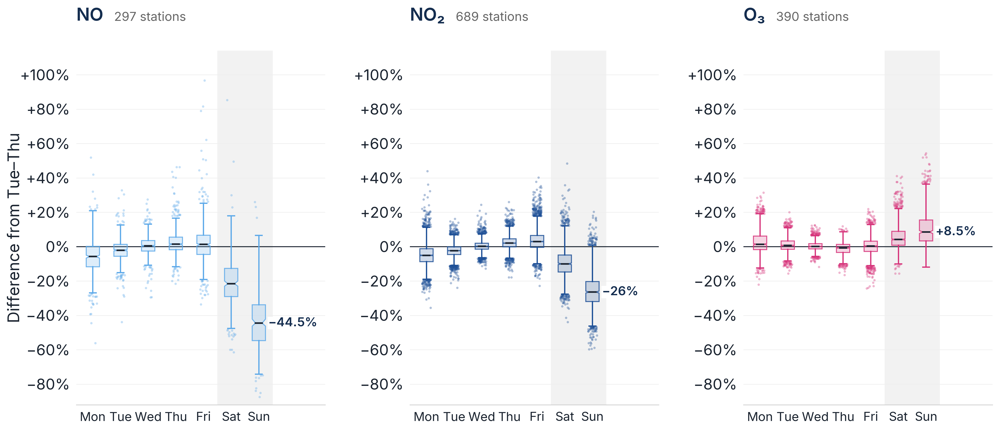

S03B_weekday_particles.png


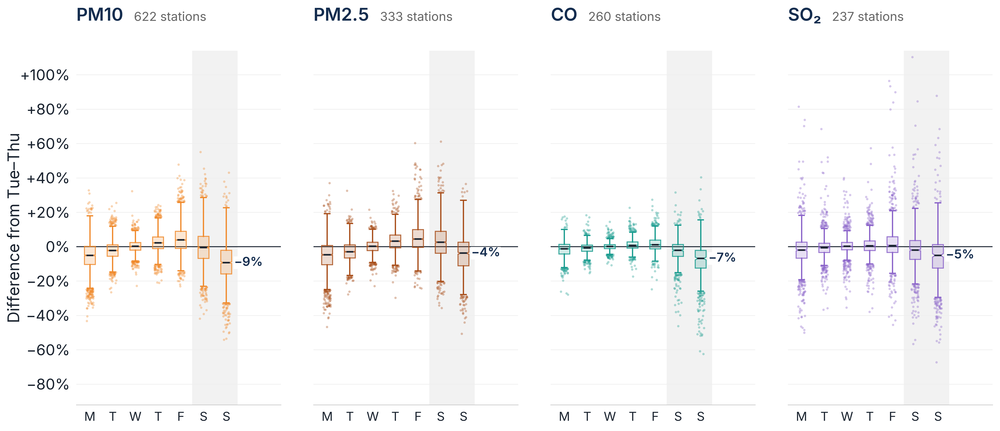

In [6]:
def median_notch(records, day):
    column = 'relative_' + day
    groups = [g.to_numpy() for _, g in records[['AirQualityStation', column]].dropna().groupby('AirQualityStation')[column]]
    rng = np.random.default_rng(20261107)
    medians = np.empty(4000)
    for i in range(4000):
        medians[i] = np.median(np.concatenate([groups[j] for j in rng.integers(0, len(groups), len(groups))]))
    return tuple(100 * (np.exp(np.percentile(medians, [2.5, 97.5])) - 1))


def weekly():
    data = fig_read('week_profile.csv')
    effects = fig_read('week_effects.csv')
    days = ['mon', 'tue', 'wed', 'thu', 'fri', 'sat', 'sun']
    counts = {'NO': 297, 'NO2': 689, 'O3': 390, 'PM10': 622, 'PM2.5': 333, 'CO': 260, 'SO2': 237}
    sunday = {'NO': -44.5, 'NO2': -26, 'O3': 8.5, 'PM10': -9, 'PM2.5': -4, 'CO': -7, 'SO2': -5}
    groups = [('3A', 'S03A_weekday_gases', ['NO', 'NO2', 'O3'], 'The week separates NO and NO₂ from ozone'), ('3B', 'S03B_weekday_particles', ['PM10', 'PM2.5', 'CO', 'SO2'], 'Particles, CO and SO₂ show a weak weekly rhythm')]
    for slide, name, pollutants, title in groups:
        fig = frame()
        fig.set_size_inches(16, 8.4)
        grid = fig.add_gridspec(1, len(pollutants), left=0.085, right=0.98, bottom=0.16, top=0.82, wspace=0.34 if len(pollutants) <= 3 else 0.16)
        scale_label = None
        headers = []
        for index, pollutant in enumerate(pollutants):
            ax = fig.add_subplot(grid[0, index])
            part = data.loc[data.pollutant.eq(pollutant)].set_index('day').loc[days]
            assert len(part) == 7
            assert part.percent_p25.le(part.percent_median).all()
            assert part.percent_median.le(part.percent_p75).all()
            ax.set_axisbelow(True)
            ax.grid(axis='y', color='#eeeeee', lw=0.7)
            ax.axvspan(4.5, 6.5, color='#f2f2f2', lw=0, zorder=0)
            ax.axhline(0, color=INK, lw=1.05)
            from matplotlib.cbook import boxplot_stats
            records = effects.loc[effects.pollutant.eq(pollutant)]
            whisker_ends, beyond = ({}, 0)
            jitter = np.random.default_rng(1)
            for x, row in enumerate(part.itertuples()):
                stats = boxplot_stats(records['relative_' + days[x]].dropna().to_numpy(), whis=1.5)[0]
                pct = lambda v: 100 * (np.exp(v) - 1)
                assert abs(pct(stats['q1']) - row.percent_p25) < 0.05 and abs(pct(stats['q3']) - row.percent_p75) < 0.05
                lo, hi = (pct(stats['whislo']), pct(stats['whishi']))
                whisker_ends[days[x]] = (lo, hi)
                beyond += len(stats['fliers'])
                colour = COLOURS[pollutant]
                outliers = pct(np.asarray(stats['fliers']))
                ax.scatter(x + jitter.uniform(-0.16, 0.16, len(outliers)), outliers, s=7, color=colour, alpha=0.35, lw=0, zorder=1.5)
                ax.plot([x, x], [lo, row.percent_p25], color=colour, lw=1.4, zorder=2)
                ax.plot([x, x], [row.percent_p75, hi], color=colour, lw=1.4, zorder=2)
                for end in (lo, hi):
                    ax.plot([x - 0.12, x + 0.12], [end, end], color=colour, lw=1.4, zorder=2)
                assert abs(pct(np.median(records['relative_' + days[x]].dropna())) - row.percent_median) < 0.05
                low_n, high_n = median_notch(records, days[x])
                low_n, high_n = max(low_n, row.percent_p25), min(high_n, row.percent_p75)
                w, m = 0.24, row.percent_median
                outline = [(x - w, row.percent_p25), (x - w, low_n), (x - w / 2, m), (x - w, high_n), (x - w, row.percent_p75),
                           (x + w, row.percent_p75), (x + w, high_n), (x + w / 2, m), (x + w, low_n), (x + w, row.percent_p25)]
                ax.add_patch(Polygon(outline, closed=True, facecolor=to_rgba(colour, 0.2), edgecolor=to_rgba(colour, 0.85), lw=1.1, zorder=3))
                ax.plot([x - w / 2, x + w / 2], [m] * 2, color=INK, lw=1.8, zorder=4)
            lower, upper = (-92, 114)
            ticks = [-80, -60, -40, -20, 0, 20, 40, 60, 80, 100]
            assert min((v[0] for v in whisker_ends.values())) >= lower and max((v[1] for v in whisker_ends.values())) <= upper, 'Axis would clip a whisker'
            every = 100 * (np.exp(records[['relative_' + d for d in days]].stack()) - 1)
            assert lower <= every.min() and every.max() <= upper, 'Axis would clip an outlier'
            ax.set(xlim=(-0.6, 8.4), ylim=(lower, upper), xticks=range(7), xticklabels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], yticks=ticks)
            actual_count = records.AirQualityStation.nunique()
            assert actual_count == counts[pollutant] == int(part.monitors.iloc[0])
            name_text = TextArea(NAMES[pollutant], textprops=dict(fontsize=20, fontweight='bold', color=INK))
            count_text = TextArea(f'{counts[pollutant]} stations', textprops=dict(fontsize=12, fontweight='normal', color=MUTED))
            header = AnchoredOffsetbox(loc='lower left', child=HPacker(children=[name_text, count_text], align='baseline', pad=0, sep=12), bbox_to_anchor=(0, 1.075), bbox_transform=ax.transAxes, frameon=False, pad=0, borderpad=0)
            ax.add_artist(header)
            headers.append(header)
            ax.set_yticklabels([f'+{value:g}%' if value > 0 else f'−{abs(value):g}%' if value < 0 else '0%' for value in ticks])
            if len(pollutants) > 3:
                ax.set_xticklabels(['M', 'T', 'W', 'T', 'F', 'S', 'S'])
                if index > 0:
                    ax.set_yticklabels([])
            ax.tick_params(axis='y', labelsize=17, length=0, pad=7)
            ax.tick_params(axis='x', labelsize=12.5, length=0, pad=8)
            ax.spines['left'].set_visible(False)
            ax.spines['bottom'].set_color('#cccccc')
            value = sunday[pollutant]
            sunday_label = f'+{value:g}%' if value > 0 else f'−{abs(value):g}%'
            label_y = float(part.loc['sun', 'percent_median'])
            label = ax.text(6.34, label_y, sunday_label, va='center', ha='left', fontsize=14, weight='semibold', bbox=dict(facecolor='white', edgecolor='none', pad=0.5))
            assert abs(float(part.loc['sun', 'percent_median']) - value) < 0.6
            fig.canvas.draw()
            bounds = ax.get_window_extent()
            label_bounds = label.get_window_extent()
            assert bounds.x0 <= label_bounds.x0 <= label_bounds.x1 <= bounds.x1
            assert bounds.y0 <= label_bounds.y0 <= label_bounds.y1 <= bounds.y1, 'Sunday label must fit the axis'
        fig.supylabel('Difference from Tue–Thu', x=0.018, y=0.49, fontsize=18)
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        bounds = [axis.get_tightbbox(renderer) for axis in fig.axes]
        gaps = [right.x0 - left.x1 for left, right in zip(bounds, bounds[1:])]
        assert min(gaps) > 20, 'Weekly panels and headers need breathing room'
        if scale_label is not None:
            title_box = headers[0].get_window_extent(renderer)
            label_box = scale_label.get_window_extent(renderer)
            assert title_box.y0 - label_box.y1 > 5, 'NO scale label must not touch the heading'
        alt = 'Three spacious weekday panels for NO, NO₂ and ozone, with station counts and notched median/quartile boxes (notch = 95% station-bootstrap interval of the median). Classic boxplots with Tukey whiskers; station-years beyond the whiskers are small translucent dots; all panels share one scale.' if slide == '3A' else 'Four weekday panels for PM10, PM2.5, CO and SO₂, with station counts, saved median/quartile boxes with the same notches, and the same scale and whisker rule as the NO, NO₂ and ozone panels.'
        save_figure(fig, name, slide)


weekly()

## 3. The 2020 lockdown

In [7]:
LOCKDOWN_POLLUTANTS = CORE + ['SO2', 'CO']
WINDOWS = [('W0', '01-01', '02-22'), ('W1', '02-23', '03-09'),
           ('W2', '03-10', '05-03'), ('W3', '05-04', '05-17'),
           ('W4', '05-18', '09-30'), ('W5', '10-01', '11-05'), ('W6', '11-06', '12-31')]


TARGETS = list(range(2016, 2024))


def periods(daily, pollutant, labels, kind):
    frame = daily[['AirQualityStation', 'year', pollutant]].rename(columns={pollutant: 'value'})
    frame = frame.assign(period_id=labels)
    result = frame.groupby(['AirQualityStation', 'year', 'period_id']).value.agg(mean='mean', n_valid='count').reset_index()
    calendar = pd.DataFrame({'time': daily.time, 'year': daily.year, 'period_id': labels}).drop_duplicates(['time', 'period_id'])
    expected = calendar.groupby(['year', 'period_id']).size().rename('n_expected')
    result = result.merge(expected, on=['year', 'period_id'], validate='many_to_one')
    eligible = eligible_years()
    result = result.merge(eligible[eligible.pollutant.eq(pollutant)].drop(columns='pollutant'),
                          on=['AirQualityStation', 'year'], validate='many_to_one')
    result = result[result.n_valid.ge(.7 * result.n_expected) & result.n_valid.gt(0)].copy()
    result['pollutant'], result['kind'] = pollutant, kind
    return result


def forecast(years, means, target):
    end = target - 1 if target < 2020 else 2019
    selected = (years >= 2013) & (years <= end) & np.isfinite(means) & (means > 0)
    minimum = 3 if target < 2020 else 4
    if selected.sum() < minimum or not (selected & (years >= end - 2)).any():
        return None
    x, y = years[selected], np.log(means[selected])
    centered = x - x.mean()
    slope = np.sum(centered * (y - y.mean())) / np.sum(centered * centered)
    intercept = y.mean() - slope * (x.mean() - end)
    return intercept + slope * (target - end)


def departures(aggregates):
    rows = []
    for (pollutant, kind, period, station), part in aggregates.groupby(
            ['pollutant', 'kind', 'period_id', 'AirQualityStation'], sort=True):
        years, means = part.year.to_numpy(), part['mean'].to_numpy()
        actual = dict(zip(years, means))
        for target in TARGETS:
            if target not in actual:
                continue
            expected_log = forecast(years, means, target)
            if expected_log is not None:
                rows.append({'pollutant': pollutant, 'kind': kind, 'period_id': period,
                             'AirQualityStation': station, 'target_year': target,
                             'departure': np.log(actual[target]) - expected_log})
    return pd.DataFrame(rows)


def summarize(stations):
    rows = []
    for (pollutant, kind, period), part in stations.groupby(['pollutant', 'kind', 'period_id'], sort=False):
        wide = part.pivot(index='AirQualityStation', columns='target_year', values='departure').reindex(columns=TARGETS)
        matrix = wide.to_numpy()
        counts = np.isfinite(matrix).sum(axis=0)
        point = np.array([np.nanmedian(matrix[:, i]) if counts[i] >= 10 else np.nan for i in range(8)])
        reference = point[:4]
        supported = np.isfinite(reference).all()
        mean = float(reference.mean()) if supported else np.nan
        scale = float(reference.std(ddof=1) * np.sqrt(1.25)) if supported else np.nan
        for i, target in enumerate(TARGETS):
            z = (point[i] - mean) / scale if scale > 0 and np.isfinite(point[i]) else np.nan
            decision = ('insufficient support' if not np.isfinite(z) else
                        'beyond ordinary variation' if abs(z) > 3.18 else
                        'uncertain' if abs(z) > 2.35 else 'within ordinary variation')
            rows.append({'pollutant': pollutant, 'kind': kind, 'period_id': period,
                         'target_year': target, 'n': int(counts[i]), 'median_departure': point[i],
                         'percent': 100 * np.expm1(point[i]), 'prediction95_low': mean - 3.18 * scale,
                         'prediction95_high': mean + 3.18 * scale,
                         'decision': decision if target >= 2020 else 'placebo reference'})
    return pd.DataFrame(rows)


daily = raw_daily()
daily = daily[daily.time.dt.strftime('%m-%d').ne('02-29')].reset_index(drop=True)
month_day = daily.time.dt.strftime('%m-%d')
window = np.full(len(daily), '', dtype=object)
for label, first, last in WINDOWS:
    window[(month_day >= first) & (month_day <= last)] = label
pieces = []
for pollutant in LOCKDOWN_POLLUTANTS:
    pieces.append(periods(daily, pollutant, window, 'window'))
    pieces.append(periods(daily, pollutant, np.repeat('FY', len(daily)), 'annual'))
lockdown_stations = departures(pd.concat(pieces, ignore_index=True))
save(summarize(lockdown_stations), 'lockdown_summary.csv')
del daily

lockdown_summary.csv: 384 rows


**Lockdown.** 2020 against each station's 2013–2019 trend, with the band of ordinary forecast errors from 2016–2019; then the seven phases of 2020.

S03C_lockdown_window.png


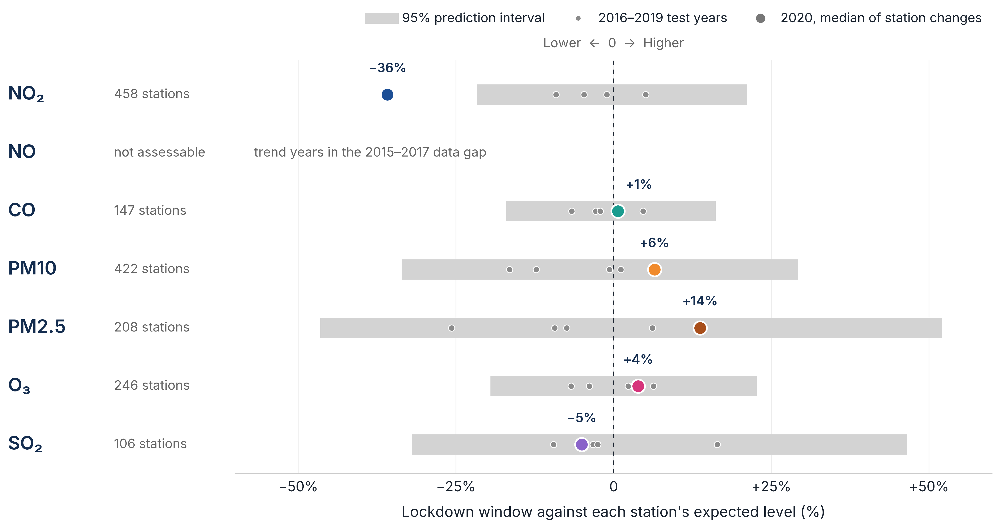

S03D_lockdown_phases.png


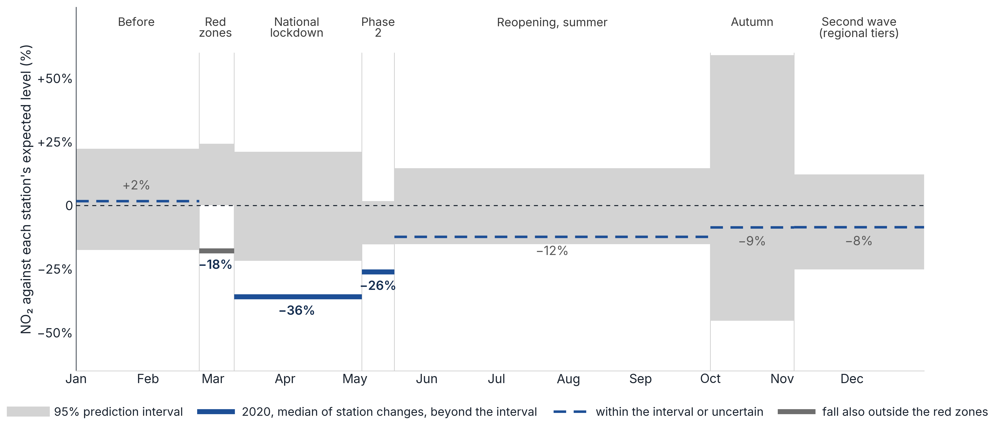

S03E_lockdown_phases_others.png


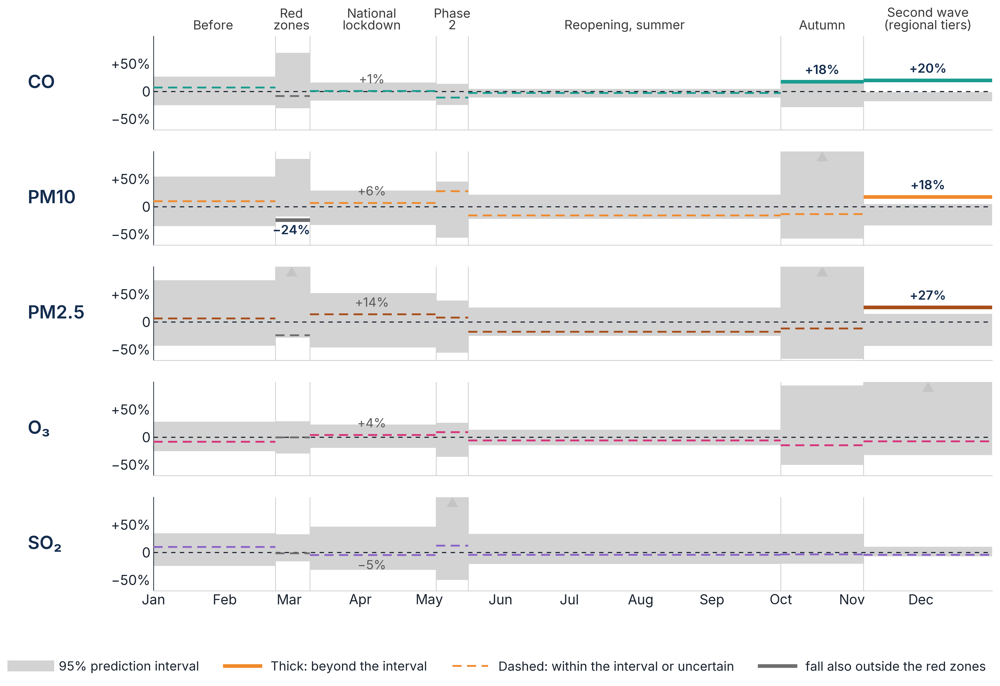

In [8]:
def lockdown_window():
    rows = fig_read('lockdown_summary.csv')
    tests = rows.loc[rows.target_year.lt(2020) & rows.period_id.eq('W2')]
    rows = rows.loc[rows.target_year.eq(2020) & rows.period_id.eq('W2')].set_index('pollutant')
    order = ['NO2', 'NO', 'CO', 'PM10', 'PM2.5', 'O3', 'SO2']
    expected = {'NO2': (458, -35.8), 'PM10': (422, 6.5), 'PM2.5': (208, 13.7), 'O3': (246, 3.9), 'SO2': (106, -5.0), 'CO': (147, 0.7)}
    fig = frame()
    fig.set_size_inches(16, 8.4)
    ax = fig.add_axes([0.25, 0.14, 0.71, 0.74])
    pct = lambda value: 100 * (np.exp(value) - 1)
    BAND = '#D3D3D3'
    for y, pollutant in enumerate(order):
        ax.text(-0.3, y, NAMES[pollutant], transform=ax.get_yaxis_transform(), fontsize=20, weight='bold', va='center', color=INK)
        if pollutant not in rows.index:
            ax.text(-0.16, y, 'not assessable', transform=ax.get_yaxis_transform(), fontsize=12, va='center', color=MUTED)
            ax.text(-57, y, 'trend years in the 2015–2017 data gap', ha='left', va='center', fontsize=14, color=MUTED)
            continue
        row = rows.loc[pollutant]
        low, high = (pct(row.prediction95_low), pct(row.prediction95_high))
        outside = not row.prediction95_low <= row.median_departure <= row.prediction95_high
        ax.plot([low, high], [y, y], color=BAND, lw=22, solid_capstyle='butt', zorder=1)
        test = tests.loc[tests.pollutant.eq(pollutant), 'median_departure'].to_numpy()
        assert len(test) == 4
        centre, width = test.mean(), 3.18 * test.std(ddof=1) * np.sqrt(1.25)
        assert np.isclose(centre - width, row.prediction95_low) and np.isclose(centre + width, row.prediction95_high), pollutant
        ax.scatter(pct(test), [y] * 4, s=46, color='#8a8a8a', edgecolor='white', lw=0.9, zorder=3)
        ax.scatter([row.percent], [y], s=210, color=COLOURS[pollutant], edgecolor='white', lw=1.8, zorder=5)
        stations, value = expected[pollutant]
        assert int(row.n) == stations and abs(row.percent - value) < 0.1, pollutant
        label = f'{round(row.percent):+d}%'.replace('-', '−')
        if abs(row.percent) < 3:
            ax.text(row.percent + 1.2, y - 0.34, label, ha='left', va='bottom', fontsize=14, weight='bold', color=INK, zorder=6)
        else:
            ax.text(row.percent, y - 0.34, label, ha='center', va='bottom', fontsize=14, weight='bold', color=INK, zorder=6)
        detail = f'{int(row.n)} stations'
        assert outside == (pollutant == 'NO2'), pollutant
        ax.text(-0.16, y, detail, transform=ax.get_yaxis_transform(), fontsize=12, va='center', color=MUTED)
    ax.axvline(0, color=INK, lw=1.2, ls=(0, (4, 4)), zorder=2)
    ax.set(xlim=(-60, 60), ylim=(len(order) - 0.5, -0.6), yticks=[], xticks=[-50, -25, 0, 25, 50])
    ax.set_xticklabels(['−50%', '−25%', '0', '+25%', '+50%'])
    ax.tick_params(axis='x', labelsize=15, length=0, pad=8)
    ax.grid(axis='x', color='#ededed', lw=0.8)
    ax.set_axisbelow(True)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_color('#cccccc')
    ax.set_xlabel("Lockdown window against each station's expected level (%)", fontsize=16, labelpad=12)
    ax.text(0.5, 1.03, 'Lower  ←  0  →  Higher', transform=ax.transAxes, ha='center', fontsize=13, color=MUTED)
    from matplotlib.lines import Line2D
    ax.legend([Line2D([], [], color=BAND, lw=12), Line2D([], [], marker='o', ls='', ms=6, color='#8a8a8a', markeredgecolor='white'), Line2D([], [], marker='o', ls='', ms=11, color='#777777', markeredgecolor='white')], ['95% prediction interval', '2016–2019 test years', PHASE_LEGEND], loc='lower right', bbox_to_anchor=(1, 1.06), ncol=3, frameon=False, fontsize=12)
    save_figure(fig, 'S03C_lockdown_window', '3C')


def phase_rows(kind='window'):
    rows = fig_read('lockdown_summary.csv' if kind == 'window' else 'lockdown_weekly.csv')
    return rows.loc[rows.target_year.eq(2020) & rows.kind.eq(kind)]


def phase_day(month_day, extra=0):
    import datetime as dt
    return dt.date(2021, int(month_day[:2]), int(month_day[3:])) + dt.timedelta(days=extra)


def phase_steps(ax, pollutant, rows, label='all', ylim=(-65, 78), phase_labels=True, label_size=15, widths=(6, 3), gap=3.5):
    import datetime as dt
    pct = lambda value: 100 * (np.exp(value) - 1)
    BAND = '#D3D3D3'
    rows = rows.loc[rows.pollutant.eq(pollutant)].set_index('period_id')
    for code, name, start, end in PHASES_2020:
        row = rows.loc[code]
        x0, x1 = (phase_day(start), phase_day(end, 1))
        low, high = (pct(row.prediction95_low), pct(row.prediction95_high))
        beyond = not row.prediction95_low <= row.median_departure <= row.prediction95_high
        assert beyond == (row.decision == 'beyond ordinary variation'), (pollutant, code)
        ax.fill_between([x0, x1], max(low, ylim[0]), min(high, ylim[1]), color=BAND, lw=0, zorder=1)
        if high > ylim[1]:
            ax.text(x0 + (x1 - x0) / 2, ylim[1] - 1, '▲', ha='center', va='top', fontsize=MIN_FONT, color='#C4C4C4', zorder=2)
        colour = '#6E6E6E' if code == 'W1' else COLOURS[pollutant]
        ax.plot([x0, x1], [row.percent] * 2, color=colour, lw=widths[0] if beyond else widths[1], ls='-' if beyond else (0, (5, 3)), solid_capstyle='butt', dash_capstyle='butt', zorder=3)
        mid = x0 + (x1 - x0) / 2
        if label == 'all' or (label == 'beyond' and (beyond or code == 'W2')):
            above = row.percent > 0
            ax.text(mid, row.percent + (gap if above else -gap), f'{round(row.percent):+d}%'.replace('-', '−').replace('+0', '0'), ha='center', va='bottom' if above else 'top', fontsize=label_size, weight='bold' if beyond else 'normal', color=INK if beyond else '#5A5A5A', zorder=4)
        if phase_labels:
            ax.text(mid, ylim[1] - 4, name, ha='center', va='top', fontsize=MIN_FONT, color='#3A3A3A', linespacing=1.0)
        if code != 'W0':
            ax.axvline(x0, color='#cccccc', lw=0.8, zorder=0, ymax=(ylim[1] - 18 - ylim[0]) / (ylim[1] - ylim[0]) if phase_labels else 1)
    ax.axhline(0, color=INK, lw=1.2, ls=(0, (4, 4)), zorder=2)
    ax.set_xticks([dt.date(2021, m, 1) for m in range(1, 13)])
    ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
    ax.set_xlim(dt.date(2021, 1, 1), dt.date(2022, 1, 1))
    ax.set_ylim(*ylim)
    ticks = [t for t in (-50, -25, 0, 25, 50, 75, 100) if ylim[0] <= t <= ylim[1] - 10]
    ax.set_yticks(ticks)
    ax.set_yticklabels([f'{t:+d}%'.replace('-', '−') if t else '0' for t in ticks])
    ax.tick_params(length=0)
    ax.spines['bottom'].set_color('#cccccc')


def phase_legend(ax, weekly=False, ncol=4):
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], color='#D3D3D3', lw=12), Line2D([], [], color=COLOURS['NO2'], lw=6), Line2D([], [], color=COLOURS['NO2'], lw=3, ls=(0, (5, 3))), Line2D([], [], color='#6E6E6E', lw=6)]
    labels = ['95% prediction interval', PHASE_LEGEND + ', beyond the interval', 'within the interval or uncertain', 'fall also outside the red zones']
    if weekly:
        handles.append(Line2D([], [], color=COLOURS['NO2'], lw=1.4, alpha=0.35))
        labels.append('week by week')
    return (handles, labels)


def lockdown_phases(weekly=False):
    import datetime as dt
    rows = phase_rows()
    expected = {'W2': (458, -35.8), 'W3': (446, -26.0), 'W4': (465, -12.3), 'W5': (451, -8.5), 'W6': (458, -8.5)}
    no2 = rows.loc[rows.pollutant.eq('NO2')].set_index('period_id')
    for code, (stations, value) in expected.items():
        assert int(no2.loc[code, 'n']) == stations and abs(no2.loc[code, 'percent'] - value) < 0.1, code
    fig = frame()
    fig.set_size_inches(16, 8.4)
    ax = fig.add_axes([0.08, 0.16, 0.88, 0.72])
    if weekly:
        week = phase_rows('week').query("pollutant == 'NO2' and period_id != 'B53'")
        centres = [dt.date(2021, 1, 1) + dt.timedelta(days=7 * (int(code[1:]) - 1) + 3) for code in week.period_id]
        ax.plot(centres, week.percent, color=COLOURS['NO2'], lw=1.4, alpha=0.35, zorder=2)
    phase_steps(ax, 'NO2', rows)
    ax.set_ylabel("NO₂ against each station's expected level (%)", fontsize=16)
    handles, labels = phase_legend(ax, weekly)
    ax.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=len(labels), frameon=False, fontsize=MIN_FONT, handlelength=2.8, columnspacing=1.4)
    if weekly:
        save_figure(fig, 'B21_lockdown_phases_weekly', 'B21')
    else:
        save_figure(fig, 'S03D_lockdown_phases', '3D')


def lockdown_phases_others():
    rows = phase_rows()
    checks = {('PM10', 'W1'): -24.5, ('PM10', 'W6'): 17.7, ('PM2.5', 'W6'): 26.5, ('CO', 'W5'): 17.7, ('CO', 'W6'): 20.1}
    for (pollutant, code), value in checks.items():
        row = rows.loc[rows.pollutant.eq(pollutant) & rows.period_id.eq(code)].iloc[0]
        assert abs(row.percent - value) < 0.1 and row.decision == 'beyond ordinary variation', (pollutant, code)
    assert not rows.loc[rows.pollutant.eq('SO2')].decision.eq('beyond ordinary variation').any()
    assert 'NO' not in set(rows.pollutant)
    fig = frame()
    fig.set_size_inches(16, 11)
    ylim = (-70, 100)
    order = ['CO', 'PM10', 'PM2.5', 'O3', 'SO2']
    top, height, gap = (0.9, 0.13, 0.03)
    y = top
    for k, pollutant in enumerate(order):
        y -= height
        ax = fig.add_axes([0.17, y, 0.8, height])
        y -= gap
        ax.text(-0.15, 0.5, NAMES[pollutant], transform=ax.transAxes, fontsize=20, weight='bold', color=INK, va='center')
        phase_steps(ax, pollutant, rows, label='beyond', ylim=ylim, phase_labels=False, label_size=MIN_FONT, widths=(4, 2), gap=9)
        ax.set_yticks([-50, 0, 50])
        ax.set_yticklabels(['−50%', '0', '+50%'])
        if pollutant != order[-1]:
            ax.set_xticklabels([])
        if k == 0:
            for code, name, start, end in PHASES_2020:
                ax.text(phase_day(start) + (phase_day(end, 1) - phase_day(start)) / 2, ylim[1] + 8, name, ha='center', va='bottom', fontsize=MIN_FONT, color='#3A3A3A', linespacing=1.0)
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], color='#D3D3D3', lw=12), Line2D([], [], color=COLOURS['PM10'], lw=4), Line2D([], [], color=COLOURS['PM10'], lw=2, ls=(0, (5, 3))), Line2D([], [], color='#6E6E6E', lw=4)]
    fig.legend(handles, ['95% prediction interval', 'Thick: beyond the interval', 'Dashed: within the interval or uncertain', 'fall also outside the red zones'], loc='lower center', bbox_to_anchor=(0.5, 0.0), ncol=4, frameon=False, handlelength=2.8, fontsize=MIN_FONT)
    save_figure(fig, 'S03E_lockdown_phases_others', '3E')


lockdown_window()
lockdown_phases()
lockdown_phases_others()

## 4. Seasonal calendars

In [9]:
MONTHS = np.arange(1, 13)


FULL = [f'm{month}' for month in MONTHS]


MINIMUM_YEARS = {'NO2': 4, 'PM10': 4, 'PM2.5': 3, 'O3': 3, 'NO': 3, 'CO': 8, 'SO2': 10}


def prune_years(matrix, minimum_years=2):
    matrix = matrix[matrix.notna().sum(axis=1).ge(4)]
    if matrix.empty:
        return None
    parent = list(range(len(matrix)))

    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for month in range(12):
        years = np.flatnonzero(matrix.notna().to_numpy()[:, month])
        for year in years[1:]:
            parent[root(year)] = root(years[0])
    roots = np.array([root(i) for i in range(len(matrix))])
    matrix = matrix[roots == np.bincount(roots).argmax()]
    return None if matrix.notna().sum(axis=0).lt(minimum_years).any() else matrix


def two_way_months(matrix):
    values = matrix.to_numpy(float)
    seasonal = np.zeros(12)
    for _ in range(500):
        annual = np.nanmean(values - seasonal, axis=1)
        update = np.nanmean(values - annual[:, None], axis=0)
        update -= update.mean()
        converged = np.max(np.abs(update - seasonal)) < 1e-10
        seasonal = update
        if converged:
            break
    return seasonal


def calendar_estimates(months):
    rows = []
    for (pollutant, station), part in months.groupby(['pollutant', 'AirQualityStation']):
        matrix = part.pivot(index='year', columns='month', values='lm').reindex(columns=MONTHS)
        matrix = prune_years(matrix)
        if matrix is None:
            continue
        row = {'pollutant': pollutant, 'AirQualityStation': station, 'n_years': len(matrix),
               'complete_years': int(matrix.notna().all(axis=1).sum()), 'cells': int(matrix.notna().sum().sum())}
        row.update(dict(zip(FULL, two_way_months(matrix))))
        for name, parity in [('even', 0), ('odd', 1)]:
            half = prune_years(matrix[matrix.index % 2 == parity], minimum_years=1)
            values = two_way_months(half) if half is not None else np.full(12, np.nan)
            row.update({f'{name}_m{m}': v for m, v in zip(MONTHS, values)})
        rows.append(row)
    return pd.DataFrame(rows)


def fuzzy_c_means(x, groups, fuzzifier, starts, rng):
    best = None
    for _ in range(starts):
        membership = rng.dirichlet(np.ones(groups), size=len(x))
        for _ in range(1000):
            weight = membership ** fuzzifier
            centres = (weight.T @ x) / weight.sum(axis=0)[:, None]
            squared = np.maximum(((x[:, None, :] - centres[None]) ** 2).sum(-1), 1e-12)
            inverse = squared ** (-1.0 / (fuzzifier - 1))
            update = inverse / inverse.sum(axis=1, keepdims=True)
            done = np.abs(update - membership).max() < 1e-7
            membership = update
            if done:
                break
        objective = float(((membership ** fuzzifier) * squared).sum())
        if best is None or objective < best[2]:
            best = membership, centres, objective
    return best


def fuzzy_validity(x, membership, centres):
    n, groups = membership.shape
    pc = float((membership ** 2).sum() / n)
    squared = ((x[:, None, :] - centres[None]) ** 2).sum(-1)
    separation = min(((centres[i] - centres[j]) ** 2).sum()
                     for i in range(groups) for j in range(i + 1, groups))
    return {'npc': (groups * pc - 1) / (groups - 1),
            'xie_beni': float(((membership ** 2) * squared).sum() / (n * separation))}


def gaussian_reference(x, rng):
    eigenvalues, eigenvectors = np.linalg.eigh(np.cov(x, rowvar=False, ddof=0))
    return x.mean(0) + rng.standard_normal(x.shape) @ (eigenvectors * np.sqrt(np.clip(eigenvalues, 0, None))).T


def winter_trap(membership, areas):
    group = int(np.argmax([membership[areas == 'North-East', j].mean() for j in range(membership.shape[1])]))
    return group


def strict_annual_sample(pollutant):
    annual = read('common_annual.csv')
    keys = eligible_years()
    annual = annual[annual.pollutant.eq(pollutant)].merge(keys, on=['AirQualityStation', 'year', 'pollutant'])
    annual = annual.merge(registry()[['AirQualityStation', 'class']], on='AirQualityStation')
    annual = annual[annual['class'].isin(['UT', 'UB', 'SB', 'ST', 'RB', 'IN'])]
    if pollutant == 'O3':
        annual = annual[annual['class'].ne('UT')]
    counts = annual.groupby('AirQualityStation').year.transform('size')
    annual = annual[counts.ge(MINIMUM_YEARS[pollutant])]
    if annual.loc[annual['class'].eq('ST'), 'AirQualityStation'].nunique() < 10:
        annual = annual[annual['class'].ne('ST')]
    return annual.sort_values(['AirQualityStation', 'year']).reset_index(drop=True)


def discarded_strict_draws(pollutant, eligible_months, rng):
    sample = strict_annual_sample(pollutant).AirQualityStation.unique()
    counts = eligible_months[eligible_months.pollutant.eq(pollutant) & eligible_months.AirQualityStation.isin(sample)]
    counts = counts.groupby(['AirQualityStation', 'month']).size().unstack().reindex(columns=MONTHS)
    n = int(counts.ge(2).all(axis=1).sum())
    for _ in range(20):
        rng.dirichlet(np.ones(2), size=n)


def null_validity(x, seed):
    rng = np.random.default_rng(seed)
    z = gaussian_reference(x, rng)
    membership, centres, _ = fuzzy_c_means(z, 2, 2.0, 3, rng)
    return fuzzy_validity(z, membership, centres)


def fuzzy_tables(calendars, eligible_months):
    reg = registry().set_index('AirQualityStation')
    rng = np.random.default_rng(SEED)
    summaries, members, centre_rows = [], [], []
    for i, pollutant in enumerate(POLLUTANTS):
        part = calendars[calendars.pollutant.eq(pollutant)].set_index('AirQualityStation')
        raw = part[FULL].to_numpy(float)
        mean, sd = raw.mean(0), raw.std(0, ddof=0)
        x = (raw - mean) / sd
        membership, centres, _ = fuzzy_c_means(x, 2, 2.0, 20, rng)
        observed = fuzzy_validity(x, membership, centres)
        null = pd.DataFrame(Parallel(n_jobs=-1, prefer='threads')(
            delayed(null_validity)(x, SEED + 1000 * i + draw) for draw in range(200)))
        areas = reg.loc[part.index, 'ripartizione'].to_numpy()
        group = winter_trap(membership, areas)
        north = membership[:, group]
        summaries.append({'pollutant': pollutant, 'n_relaxed': len(part),
                          'share_between_relaxed': float(((north >= .3) & (north <= .7)).mean()),
                          **observed, 'null_npc_p95': null.npc.quantile(.95),
                          'null_npc_median': null.npc.median(), 'null_xb_p05': null.xie_beni.quantile(.05),
                          'groups_beyond_chance': bool(observed['npc'] > null.npc.quantile(.95)
                                                     and observed['xie_beni'] < null.xie_beni.quantile(.05))})
        members.append(pd.DataFrame({'pollutant': pollutant, 'AirQualityStation': part.index,
                                     'membership_north': north}))
        for index, name in [(group, 'winter-trap side'), (1 - group, 'year-round side')]:
            for month in MONTHS:
                centre_rows.append({'pollutant': pollutant, 'group': name, 'month': month,
                                    'value_log': centres[index, month - 1] * sd[month - 1] + mean[month - 1]})
        if pollutant not in CORE:
            discarded_strict_draws(pollutant, eligible_months, rng)
        print(f'{pollutant}: fuzzy fit and 200 null sets complete', flush=True)
    members = pd.concat(members, ignore_index=True).merge(
        reg[['class', 'ripartizione', 'region', 'Longitude', 'Latitude', 'Altitude']].reset_index(),
        on='AirQualityStation', validate='many_to_one')
    return pd.DataFrame(summaries), members.round(5), pd.DataFrame(centre_rows).round(5)


def three_group_tables(profiles, members):
    calendar_rows, summary_rows = [], []
    names = ['year-round', 'third', 'winter-trap']
    for i, pollutant in enumerate(['NO2', 'NO', 'CO', 'PM10', 'PM2.5', 'O3']):
        wide = profiles[profiles.pollutant.eq(pollutant)].pivot(index='AirQualityStation', columns='month', values='log_profile').reindex(columns=MONTHS)
        raw = wide.to_numpy(float)
        x = (raw - raw.mean(0)) / raw.std(0, ddof=0)
        two = members[members.pollutant.eq(pollutant)].set_index('AirQualityStation').membership_north.reindex(wide.index).to_numpy()
        assert not np.isnan(two).any()
        membership, _, _ = fuzzy_c_means(x, 3, 2.0, 20, np.random.default_rng(SEED + 100 * i + 3))
        labels = membership.argmax(1)
        order = np.argsort([np.median(two[labels == g]) for g in range(3)])
        logs = {}
        for name, group in zip(names, order):
            selected = labels == group
            logs[name] = np.median(raw[selected], axis=0)
            for month, value in zip(MONTHS, logs[name]):
                calendar_rows.append({'pollutant': pollutant, 'group': name, 'monitors': int(selected.sum()),
                                      'month': month, 'calendar_ratio': float(np.exp(value))})
        low, mid, high = logs['year-round'], logs['third'], logs['winter-trap']
        span = high - low
        share = float((mid - low) @ span / (span @ span))
        fitted = low + share * span
        between = (mid >= np.minimum(low, high) - 0.02) & (mid <= np.maximum(low, high) + 0.02)
        third = labels == order[1]
        summary_rows.append({'pollutant': pollutant, 'monitors': len(x),
                             'monitors_year_round': int((labels == order[0]).sum()), 'monitors_third': int(third.sum()),
                             'monitors_winter_trap': int((labels == order[2]).sum()),
                             'third_two_group_membership_median': float(np.median(two[third])),
                             'mix_share_winter_trap': share,
                             'mix_r2': float(1 - ((mid - fitted) ** 2).sum() / ((mid - mid.mean()) ** 2).sum()),
                             'months_between': int(between.sum())})
    return pd.DataFrame(calendar_rows).round(5), pd.DataFrame(summary_rows).round(4)


def adjusted_annual_means(pollutant):
    annual = strict_annual_sample(pollutant)
    codes, stations = pd.factorize(annual.AirQualityStation, sort=True)
    years = sorted(annual.year.unique())
    design = pd.get_dummies(pd.Categorical(annual.year, categories=years), drop_first=True, dtype=float).to_numpy()
    counts = np.bincount(codes)
    values = np.log(annual['mean'].to_numpy())
    mean_y = np.bincount(codes, weights=values) / counts
    mean_x = np.column_stack([np.bincount(codes, weights=design[:, j]) / counts for j in range(design.shape[1])])
    beta, _, rank, _ = linalg.lstsq(design - mean_x[codes], values - mean_y[codes], lapack_driver='gelsy')
    assert rank == len(years) - 1
    return pd.Series(np.exp(mean_y - mean_x @ beta + np.r_[0., beta].mean()), index=stations)


def same_mean_examples(months, members):
    pairs = {'PM10': [('lower', 'STA.IT1566A'), ('higher', 'STA.IT1183A')],
             'O3': [('lower', 'STA.IT2006A'), ('higher', 'STA.IT0707A')]}
    reg = registry().set_index('AirQualityStation')
    daily, eligible = raw_daily(), eligible_years()
    rows = []
    for pollutant, pair in pairs.items():
        adjusted = adjusted_annual_means(pollutant)
        for rank, station in pair:
            selected = months[months.pollutant.eq(pollutant) & months.AirQualityStation.eq(station)]
            columns = selected.assign(value=np.exp(selected.lm)).groupby('month').agg(monthly_mean=('value', 'mean'), years=('year', 'nunique')).reset_index()
            membership = float(members.loc[members.pollutant.eq(pollutant) & members.AirQualityStation.eq(station), 'membership_north'].iloc[0])
            median_days, daily_level = np.nan, np.nan
            if pollutant == 'PM10':
                years = eligible.loc[eligible.pollutant.eq(pollutant) & eligible.AirQualityStation.eq(station), 'year']
                days = daily[daily.AirQualityStation.eq(station) & daily.year.isin(years)]
                median_days, daily_level = days[pollutant].gt(50).groupby(days.year).sum().median(), 50.
            rows.append(columns.assign(pollutant=pollutant, AirQualityStation=station,
                                       municipality=reg.loc[station, 'COMUNE'], station_class=reg.loc[station, 'class'],
                                       peak_rank=rank, side='winter-trap' if membership > .5 else 'year-round',
                                       membership=membership, annual_mean=adjusted[station],
                                       median_days_above=median_days, daily_level=daily_level))
    return pd.concat(rows, ignore_index=True)


with threadpool_limits(limits=1):
    months = read('common_monthly.csv')
    estimates = calendar_estimates(months)
    profiles = estimates.melt(id_vars=['pollutant', 'AirQualityStation', 'n_years', 'complete_years', 'cells'],
                              value_vars=FULL, var_name='month', value_name='log_profile')
    profiles['month'] = profiles.month.str[1:].astype(int)
    profiles = profiles.round(5)
    save(profiles, 'calendars_profiles.csv')
    calendar_summary, members, centres = fuzzy_tables(estimates, monthly(eligible=True))
    save(calendar_summary, 'calendars_summary.csv')
    save(members, 'calendars_memberships.csv')
    save(centres, 'calendars_centres.csv')
    three, three_summary = three_group_tables(profiles, members)
    save(three, 'calendars_three_groups.csv')
    save(three_summary, 'calendars_three_groups_summary.csv')
    save(same_mean_examples(months, members), 'calendars_examples.csv')

calendars_profiles.csv: 31,980 rows


NO2: fuzzy fit and 200 null sets complete


PM10: fuzzy fit and 200 null sets complete


PM2.5: fuzzy fit and 200 null sets complete


O3: fuzzy fit and 200 null sets complete


NO: fuzzy fit and 200 null sets complete


... (4 outputs left out)

calendars_centres.csv: 168 rows


calendars_three_groups.csv: 216 rows


calendars_three_groups_summary.csv: 6 rows


calendars_examples.csv: 48 rows


**Calendars.** The shape of each station's year and its two types; a third group; two pairs with the same annual mean; the types on the map.

S04B_seasonal_calendars.png


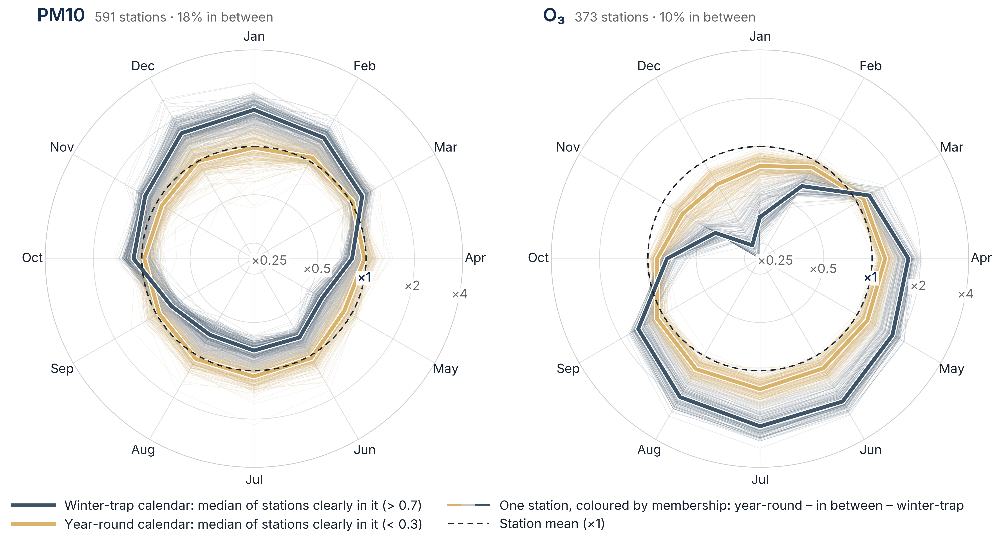

S04B3_third_calendar.png


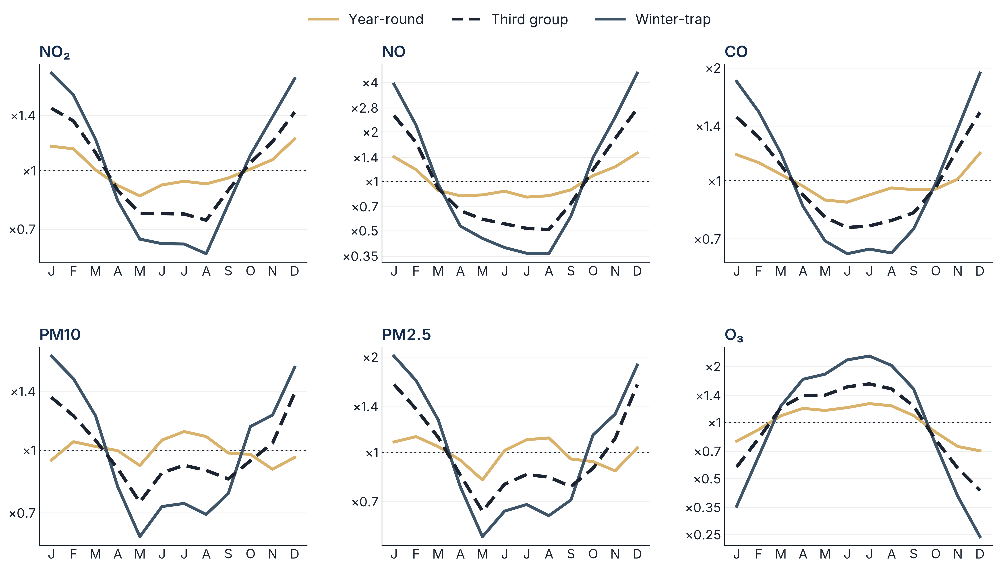

S04B2_same_mean_pm10.png


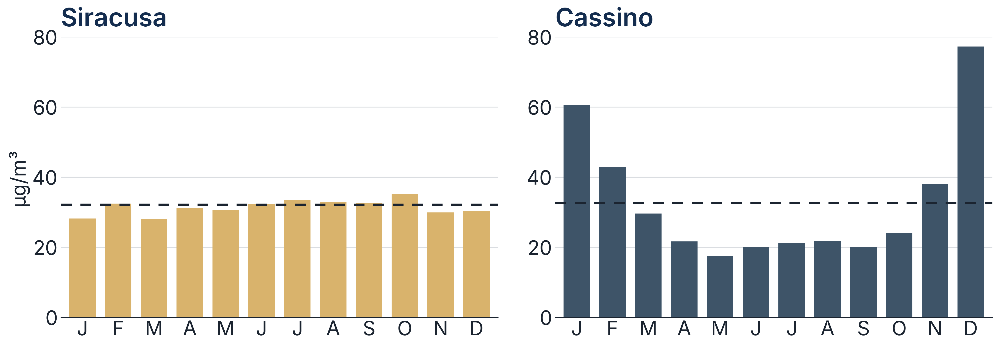

S04B2_same_mean_o3.png


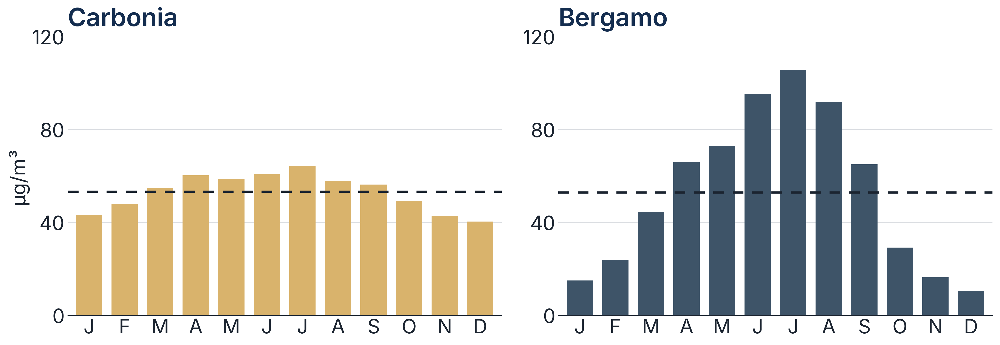

S04C_calendar_membership.png


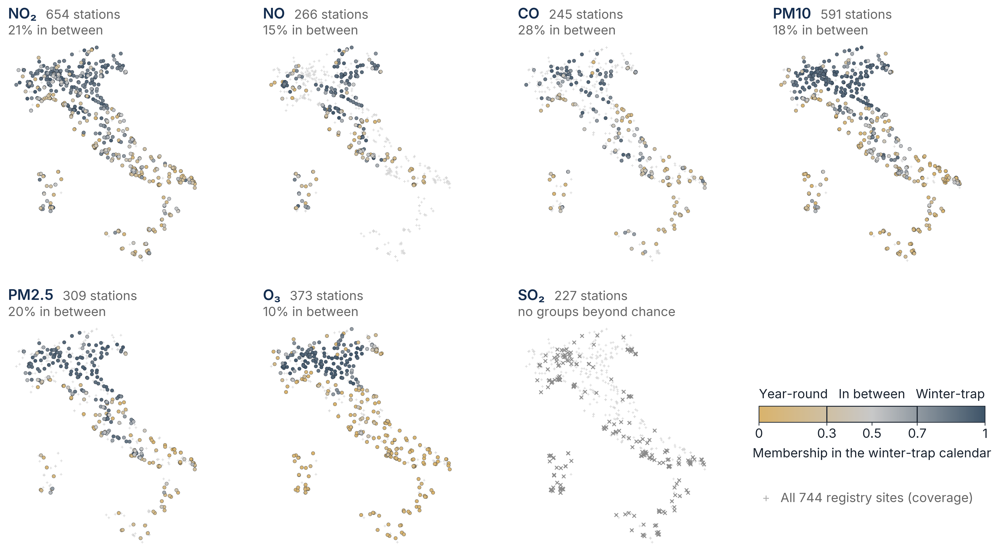

In [10]:
def clock_axes(ax, rmax, radius, rings, labels, month_labels, month_size):
    from matplotlib import patheffects
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    ring = np.linspace(0, 2 * np.pi, 240)
    ax.plot(ring, np.full(ring.size, radius(1)), color=INK, lw=1.5, ls=(0, (4, 3)), zorder=6)
    ax.set_xticks(np.arange(12) * np.pi / 6, month_labels, fontsize=month_size)
    ax.set_yticks(radius(np.array(rings)), [])
    for value, text in zip(rings, labels):
        ax.text(np.deg2rad(100), radius(value), text, fontsize=MIN_FONT, ha='center', va='center', zorder=12, color=INK if text == '×1' else MUTED, fontweight='bold' if text == '×1' else 'normal', bbox=dict(facecolor='white', edgecolor='none', alpha=0.9, pad=1.5))
    ax.set_ylim(0, rmax)
    ax.grid(color='#dddddd', lw=0.8)
    ax.spines['polar'].set_color('#cccccc')
    return patheffects


def calendar_clock():
    prof = fig_read('calendars_profiles.csv')
    memb = fig_read('calendars_memberships.csv')
    summary = fig_read('calendars_summary.csv').set_index('pollutant')
    low, high = (0.2, 4.0)
    radius = lambda r: np.log(np.clip(r, low, high)) - np.log(low)
    fig = frame()
    fig.set_size_inches(16, 8.8)
    theta = np.arange(12) * np.pi / 6
    closed = np.append(theta, theta[0])
    for j, pollutant in enumerate(['PM10', 'O3']):
        wide = prof.loc[prof.pollutant.eq(pollutant)].pivot(index='AirQualityStation', columns='month', values='log_profile')
        ratio = np.exp(wide.reindex(columns=range(1, 13)))
        u = memb.loc[memb.pollutant.eq(pollutant)].set_index('AirQualityStation').membership_north.reindex(ratio.index)
        assert u.notna().all() and len(ratio) == int(summary.loc[pollutant, 'n_relaxed'])
        between = float(((u >= 0.3) & (u <= 0.7)).mean())
        assert abs(between - summary.loc[pollutant, 'share_between_relaxed']) < 1e-09
        ax = fig.add_axes([0.04 + j * 0.48, 0.14, 0.42, 0.72], projection='polar')
        effects = clock_axes(ax, radius(high), radius, [0.25, 0.5, 1, 2, 4], ['×0.25', '×0.5', '×1', '×2', '×4'], CLOCK_MONTHS, 14)
        for station in (u - 0.5).abs().sort_values(ascending=False).index:
            r = radius(ratio.loc[station].to_numpy())
            ax.plot(closed, np.append(r, r[0]), color=MEMBERSHIP_CMAP(float(u.loc[station])), lw=0.6, alpha=0.18, zorder=2)
        for group, rows in [('year-round', ratio.loc[u < 0.3]), ('winter-trap', ratio.loc[u > 0.7])]:
            median = rows.median(axis=0).to_numpy()
            r = radius(median)
            ax.plot(closed, np.append(r, r[0]), color=BAND_COLOURS[group], lw=4.2, zorder=5, path_effects=[effects.withStroke(linewidth=6.5, foreground='white')])
        heading(ax, NAMES[pollutant], f'{len(ratio)} stations · {round(100 * between)}% in between', anchor=(-0.02, 1.06), name_size=20, detail_size=MIN_FONT)
    from matplotlib.lines import Line2D
    from matplotlib.legend_handler import HandlerTuple
    outline = [effects.withStroke(linewidth=6.5, foreground='white')]
    stations = tuple(Line2D([], [], color=BAND_COLOURS[k], lw=2) for k in ('year-round', 'in between', 'winter-trap'))
    handles = [Line2D([], [], color=BAND_COLOURS['winter-trap'], lw=4, path_effects=outline), Line2D([], [], color=BAND_COLOURS['year-round'], lw=4, path_effects=outline), stations, Line2D([], [], color=INK, lw=1.5, ls=(0, (4, 3)))]
    ax.legend(handles, ['Winter-trap calendar: median of stations clearly in it (> 0.7)', 'Year-round calendar: median of stations clearly in it (< 0.3)', 'One station, coloured by membership: year-round – in between – winter-trap', 'Station mean (×1)'], loc='upper center', bbox_to_anchor=(-0.15, -0.05), ncol=2, frameon=False, fontsize=MIN_FONT, handlelength=3.2, handler_map={tuple: HandlerTuple(ndivide=None, pad=0)})
    save_figure(fig, 'S04B_seasonal_calendars', '4B')


def third_calendar():
    table = fig_read('calendars_three_groups.csv')
    summary = fig_read('calendars_three_groups_summary.csv').set_index('pollutant')
    fig = frame()
    styles = [('year-round', BAND_COLOURS['year-round'], '-', 3.2, 'Year-round'),
              ('third', INK, (0, (4, 2)), 3.6, 'Third group'),
              ('winter-trap', BAND_COLOURS['winter-trap'], '-', 3.2, 'Winter-trap')]
    for i, pollutant in enumerate(['NO2', 'NO', 'CO', 'PM10', 'PM2.5', 'O3']):
        row, col = divmod(i, 3)
        assert summary.loc[pollutant, 'months_between'] >= 11 and summary.loc[pollutant, 'mix_r2'] > 0.9
        ax = fig.add_axes([0.06 + col * 0.32, 0.54 - row * 0.47, 0.25, 0.33])
        ax.axhline(1, color=INK, lw=1, ls=(0, (2, 3)), zorder=1)
        for group, colour, style, width, _ in styles:
            line = table.loc[table.pollutant.eq(pollutant) & table.group.eq(group)].sort_values('month')
            assert len(line) == 12
            ax.plot(range(12), line.calendar_ratio, color=colour, ls=style, lw=width, zorder=3 if group == 'third' else 2)
        ax.set_yscale('log')
        low, high = ax.get_ylim()
        ticks = [t for t in [0.25, 0.35, 0.5, 0.7, 1, 1.4, 2, 2.8, 4] if low <= t <= high]
        ax.set_yticks(ticks, [f'×{t:g}' for t in ticks])
        ax.minorticks_off()
        ax.set_xticks(range(12), list('JFMAMJJASOND'))
        ax.tick_params(length=0, labelsize=MIN_FONT)
        ax.grid(axis='y', color='#ededed', lw=0.8)
        ax.set_axisbelow(True)
        heading(ax, NAMES[pollutant], '', name_size=17)
    fig.legend([plt.Line2D([], [], color=c, ls=s, lw=3) for _, c, s, _, _ in styles], [n for *_, n in styles],
               frameon=False, fontsize=15, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 0.975))
    save_figure(fig, 'S04B3_third_calendar', '4B3')


def same_mean_example():
    table = fig_read('calendars_examples.csv')
    specs = [('PM10', 80, [0, 20, 40, 60, 80], 'S04B2_same_mean_pm10', 'Two column charts on the same 0–80 µg/m³ scale: Siracusa’s PM10 monthly means stay near its dashed annual mean all year; Cassino’s are low from April to October and reach about 60 in January and 77 in December, around the same annual mean.'), ('O3', 120, [0, 40, 80, 120], 'S04B2_same_mean_o3', 'Two column charts on the same 0–120 µg/m³ scale: Carbonia’s ozone monthly means vary gently around its dashed annual mean; Bergamo’s rise from about 11 in December to 106 in July, around the same annual mean.')]
    for pollutant, ymax, ticks, name, alt in specs:
        part = table.loc[table.pollutant.eq(pollutant)]
        fig = frame()
        fig.set_size_inches(16, 6)
        for i, rank in enumerate(['lower', 'higher']):
            mon = part.loc[part.peak_rank.eq(rank)].sort_values('month')
            assert mon.month.tolist() == list(range(1, 13)) and mon.side.nunique() == 1
            first = mon.iloc[0]
            ax = fig.add_axes([0.075 + i * 0.475, 0.13, 0.42, 0.72])
            ax.bar(mon.month, mon.monthly_mean, width=0.74, color=BAND_COLOURS[first.side], zorder=2)
            ax.axhline(first.annual_mean, color=INK, lw=2.4, ls=(0, (5, 4)), zorder=3)
            ax.set_title(first.municipality, loc='left', fontsize=28, weight='bold', color=INK, pad=12)
            ax.set_xlim(0.4, 12.6)
            ax.set_ylim(0, ymax)
            ax.set_yticks(ticks, ticks)
            ax.set_xticks(range(1, 13), list('JFMAMJJASOND'))
            ax.tick_params(length=0, labelsize=22, colors=INK)
            ax.grid(axis='y', color='#DADDE1', lw=1)
            ax.set_axisbelow(True)
            for side in ('top', 'right', 'left'):
                ax.spines[side].set_visible(False)
            ax.spines['bottom'].set_color(INK)
            if i == 0:
                ax.set_ylabel('µg/m³', fontsize=22, color=INK)
            assert mon.monthly_mean.max() < ymax
        means = part.groupby('peak_rank').annual_mean.first()
        assert abs(means['lower'] / means['higher'] - 1) <= 0.05
        assert set(part.side) == {'winter-trap', 'year-round'}
        save_figure(fig, name, '4B2')


def calendar_membership():
    members = fig_read('calendars_memberships.csv')
    summary = fig_read('calendars_summary.csv').set_index('pollutant')
    sites = fig_read('registry')
    expected = {'NO2': 654, 'NO': 266, 'CO': 245, 'PM10': 591, 'PM2.5': 309, 'O3': 373, 'SO2': 227}
    between = {'NO2': 0.21, 'NO': 0.15, 'CO': 0.28, 'PM10': 0.18, 'PM2.5': 0.2, 'O3': 0.1}
    fig = frame()
    norm = TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1)
    grid = fig.add_gridspec(2, 4, left=0.02, right=0.98, bottom=0.03, top=0.9, wspace=0.06, hspace=0.22)
    for i, p in enumerate(ML_ORDER):
        ax = fig.add_subplot(grid[i // 4, i % 4])
        part = members.loc[members.pollutant.eq(p)].copy()
        assert len(part) == expected[p] == summary.loc[p, 'n_relaxed'] and part.AirQualityStation.is_unique
        italy_axes(ax, sites)
        share = ((part.membership_north >= 0.3) & (part.membership_north <= 0.7)).mean()
        if p == 'SO2':
            assert not summary.loc[p, 'groups_beyond_chance']
            ax.scatter(part.Longitude, part.Latitude, s=16, marker='x', color='#8a8a8a', lw=0.9, zorder=2)
            two_line_heading(ax, NAMES[p], f'{len(part)} stations', 'no groups beyond chance')
        else:
            assert summary.loc[p, 'groups_beyond_chance'] and abs(share - between[p]) < 0.006
            part['distance'] = (part.membership_north - 0.5).abs()
            part = part.sort_values('distance', ascending=False)
            mark = ax.scatter(part.Longitude, part.Latitude, c=part.membership_north, cmap=MEMBERSHIP_CMAP, norm=norm, s=15, edgecolor=INK, lw=0.22, zorder=2)
            two_line_heading(ax, NAMES[p], f'{len(part)} stations', f'{share:.0%} in between')
    key = fig.add_subplot(grid[1, 3])
    key.axis('off')
    cax = key.inset_axes([0.03, 0.55, 0.94, 0.07])
    bar = fig.colorbar(mark, cax=cax, orientation='horizontal')
    bar.set_ticks([0, 0.3, 0.5, 0.7, 1], labels=['0', '0.3', '0.5', '0.7', '1'])
    bar.ax.tick_params(labelsize=11)
    for x, label, align in [(0, 'Year-round', 'left'), (0.5, 'In between', 'center'), (1, 'Winter-trap', 'right')]:
        cax.text(x, 1.5, label, transform=cax.transAxes, ha=align, fontsize=12, color=INK)
    cax.axvspan(0.3, 0.7, ymin=0, ymax=1, facecolor='none', edgecolor=INK, lw=1.2)
    cax.set_xlabel('Membership in the winter-trap calendar', fontsize=12, labelpad=8)
    key.scatter([0.06], [0.22], transform=key.transAxes, s=40, color='#b0b0b0', marker='+', lw=1)
    key.text(0.12, 0.22, 'All 744 registry sites (coverage)', transform=key.transAxes, va='center', fontsize=11, color=MUTED)
    save_figure(fig, 'S04C_calendar_membership', '4C')


calendar_clock()
third_calendar()
same_mean_example()
calendar_membership()

## 5. The area from the calendar

In [11]:
AREAS = list(RIPARTIZIONI.values())


THREE = ['North', 'Centre', 'South and Islands']


ADJACENT = {frozenset(pair) for pair in [('North-West', 'North-East'), ('North-West', 'Centre'),
                                        ('North-East', 'Centre'), ('Centre', 'South')]}


def winter_summer_features():
    daily = load_daily()
    pieces = []
    for pollutant in POLLUTANTS:
        frame = daily[['AirQualityStation', 'time', 'year', pollutant]].dropna().copy()
        frame['month'] = frame.time.dt.month
        frame['log_value'] = np.log(frame[pollutant])
        frame = frame.sort_values(['AirQualityStation', 'time'])
        years = frame.groupby('AirQualityStation').year.nunique()
        frame = frame[frame.AirQualityStation.isin(years[years.ge(3)].index)]
        monthly = frame.groupby(['AirQualityStation', 'month']).log_value.mean().unstack()
        monthly = monthly.sub(monthly.mean(axis=1), axis=0)
        ratio = monthly[[12, 1, 2]].mean(axis=1) - monthly[[6, 7, 8]].mean(axis=1)
        pieces.append(pd.DataFrame({f'{pollutant}|season_ws': ratio, f'{pollutant}|years': years}))
    return pd.concat(pieces, axis=1).sort_index()


def pair_sample(features, pollutants):
    years = [f'{p}|years' for p in pollutants]
    columns = [f'{p}|season_ws' for p in pollutants]
    return features.loc[features[years].notna().all(axis=1) & features[years].ge(3).all(axis=1), columns].dropna()


def nearest_centroid_cv(x, labels, municipalities):
    predictions = []
    for repeat in range(5):
        predicted = np.empty(len(labels), dtype=object)
        splitter = StratifiedGroupKFold(5, shuffle=True, random_state=SEED + repeat)
        for train, test in splitter.split(x, labels, municipalities):
            model = make_pipeline(StandardScaler(), NearestCentroid()).fit(x[train], labels[train])
            predicted[test] = model.predict(x[test])
        predictions.append(predicted)
    return predictions


def recall_rows(labels, predictions, grouping, classes):
    recalls = np.array([[np.mean(predicted[labels == area] == area) for area in classes]
                        for predicted in predictions])
    rows = [{'grouping': grouping, 'model': 'nearest centroid, 2 numbers', 'measure': 'recall',
             'area': area, 'value': recalls[:, i].mean(), 'low': recalls[:, i].min(),
             'high': recalls[:, i].max(), 'monitors': int((labels == area).sum())}
            for i, area in enumerate(classes)]
    balanced = recalls.mean(axis=1)
    rows.append({'grouping': grouping, 'model': 'nearest centroid, 2 numbers', 'measure': 'balanced accuracy',
                 'area': 'all', 'value': balanced.mean(), 'low': balanced.min(), 'high': balanced.max(),
                 'monitors': len(labels), 'chance': 1 / len(classes)})
    return rows


def error_direction(predictions, rng):
    wrong = predictions[predictions.predicted.ne(predictions.observed) & predictions.observed.isin(AREAS[:4])]
    adjacent = np.array([frozenset((observed, predicted)) in ADJACENT
                         for observed, predicted in zip(wrong.observed, wrong.predicted)])
    frequencies = predictions.predicted.value_counts(normalize=True).reindex(AREAS, fill_value=0)
    expected, simulations = [], np.zeros(5000)
    for observed, n in wrong.observed.value_counts().items():
        others = [area for area in AREAS if area != observed]
        probabilities = frequencies[others] / frequencies[others].sum()
        is_adjacent = np.array([frozenset((observed, area)) in ADJACENT for area in others])
        probability = probabilities[is_adjacent].sum()
        expected.append(n * probability)
        simulations += rng.binomial(n, probability, 5000)
    share = adjacent.mean()
    return len(wrong), share, sum(expected) / len(wrong), (1 + np.sum(simulations / len(wrong) >= share)) / 5001


reg = registry().set_index('AirQualityStation')
features = winter_summer_features()
sample = pair_sample(features, ['PM10', 'O3'])
assert len(sample) == 284, f'Expected 284 stations, obtained {len(sample)}'
area = reg.loc[sample.index, 'ripartizione'].to_numpy()
municipality = reg.loc[sample.index, 'PRO_COM'].to_numpy()
area3 = three_areas(area)
x = sample.to_numpy(float)
five_predictions = nearest_centroid_cv(x, area, municipality)
three_predictions = nearest_centroid_cv(x, area3, municipality)
rows = recall_rows(area, five_predictions, 'five areas', AREAS)
rows += recall_rows(area3, three_predictions, 'three areas', THREE)
predictions = pd.concat([pd.DataFrame({'observed': area, 'predicted': predicted})
                         for predicted in five_predictions], ignore_index=True)
n, observed, expected, p_value = error_direction(predictions, np.random.default_rng(SEED))
rows.append({'grouping': 'five areas', 'model': 'nearest centroid, 2 numbers',
             'measure': 'errors to neighbouring areas', 'area': 'mainland',
             'value': observed, 'expected': expected, 'p_value': p_value, 'monitors': n})
for observed_area in AREAS:
    for assigned in AREAS:
        share = np.mean([np.mean(predicted[area == observed_area] == assigned) for predicted in five_predictions])
        rows.append({'grouping': 'five areas', 'model': 'nearest centroid, 2 numbers', 'measure': 'assigned share',
                     'area': observed_area, 'assigned': assigned, 'value': share})
shuffled = []
for trial in range(100):
    labels = np.random.default_rng(SEED + 1000 + trial).permutation(area)
    predicted = nearest_centroid_cv(x, labels, municipality)[0]
    shuffled.append(np.mean([np.mean(predicted[labels == c] == c) for c in AREAS]))
rows.append({'grouping': 'five areas', 'model': 'shuffled areas (100 permutations, first repeat)',
             'measure': 'balanced accuracy', 'area': 'all', 'value': float(np.median(shuffled)),
             'low': float(np.min(shuffled)), 'high': float(np.max(shuffled)),
             'p95': float(np.quantile(shuffled, .95)), 'chance': .2})
for grouping, labels, classes in [('five areas', area, AREAS), ('three areas', area3, THREE)]:
    for label in classes:
        centre = x[labels == label].mean(axis=0)
        rows.append({'grouping': grouping, 'model': 'nearest centroid, 2 numbers', 'measure': 'centroid',
                     'area': label, 'pm10_log_ratio': centre[0], 'o3_log_ratio': centre[1]})
membership = read('calendars_memberships.csv').query("pollutant == 'PM10'").set_index('AirQualityStation').membership_north
monitors = pd.DataFrame({'AirQualityStation': sample.index, 'area': area, 'area3': area3,
                         'pm10_log_ratio': x[:, 0], 'o3_log_ratio': x[:, 1],
                         'correct_share_five': np.mean([p == area for p in five_predictions], axis=0),
                         'correct_share_three': np.mean([p == area3 for p in three_predictions], axis=0),
                         'altitude': reg.loc[sample.index, 'Altitude'].to_numpy(),
                         'region': reg.loc[sample.index, 'region'].to_numpy(),
                         'longitude': reg.loc[sample.index, 'Longitude'].to_numpy(),
                         'latitude': reg.loc[sample.index, 'Latitude'].to_numpy(),
                         'pm10_membership': membership.reindex(sample.index).to_numpy()})
monitors['recognised_five'] = monitors.correct_share_five >= .5
monitors['recognised_three'] = monitors.correct_share_three >= .5
for label in THREE:
    monitors[f'three_share_{label}'] = np.mean([p == label for p in three_predictions], axis=0)
others = pd.DataFrame({label: np.where(area3 == label, -1, monitors[f'three_share_{label}']) for label in THREE})
monitors['assigned_three'] = np.where(monitors.recognised_three, area3, others.idxmax(axis=1))
north = monitors[monitors.area3.eq('North')]
for flag, label in [(True, 'recognised'), (False, 'missed')]:
    part = north[north.recognised_three.eq(flag)]
    rows.append({'grouping': 'three areas', 'model': 'nearest centroid, 2 numbers',
                 'measure': f'North {label}: median altitude', 'area': 'North',
                 'value': float(part.altitude.median()), 'monitors': len(part),
                 'pm10_membership_median': float(part.pm10_membership.median()),
                 'regions': '; '.join(f'{key} {n}' for key, n in part.region.value_counts().items())})
save(monitors, 'place_monitors.csv')
save(pd.DataFrame(rows), 'place_metrics.csv');

place_monitors.csv: 284 rows


place_metrics.csv: 47 rows


**Area.** Winter/summer contrast of PM10 and ozone, nearest-centroid assignment to five areas, then three zones and the missed northern stations.

S04E_step1_model.png


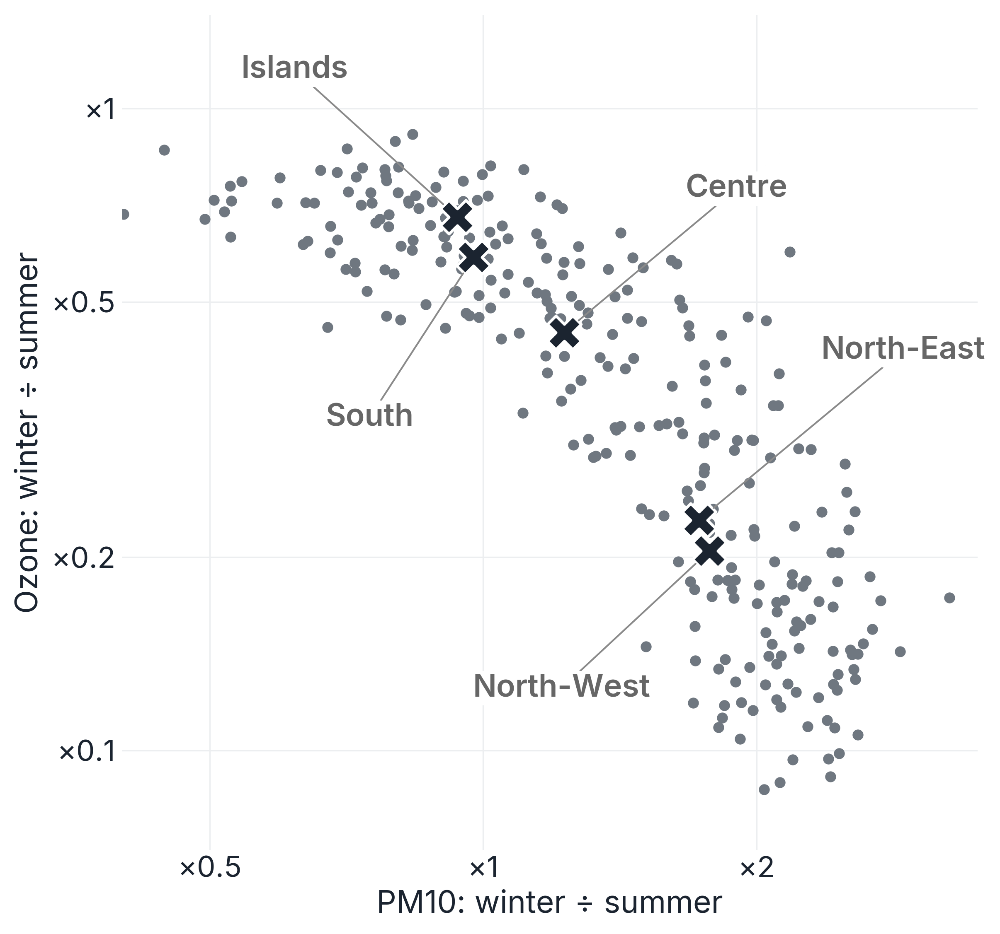

S04E_step3_north.png


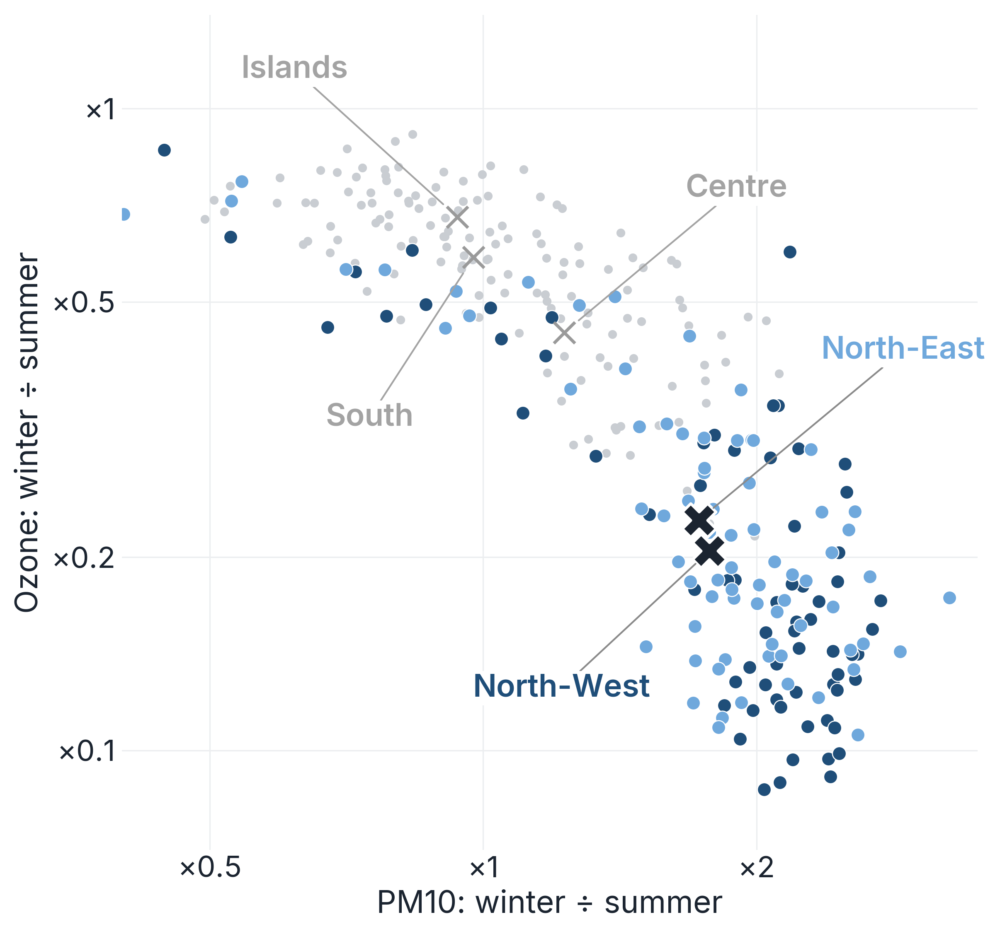

S04E_step4_south.png


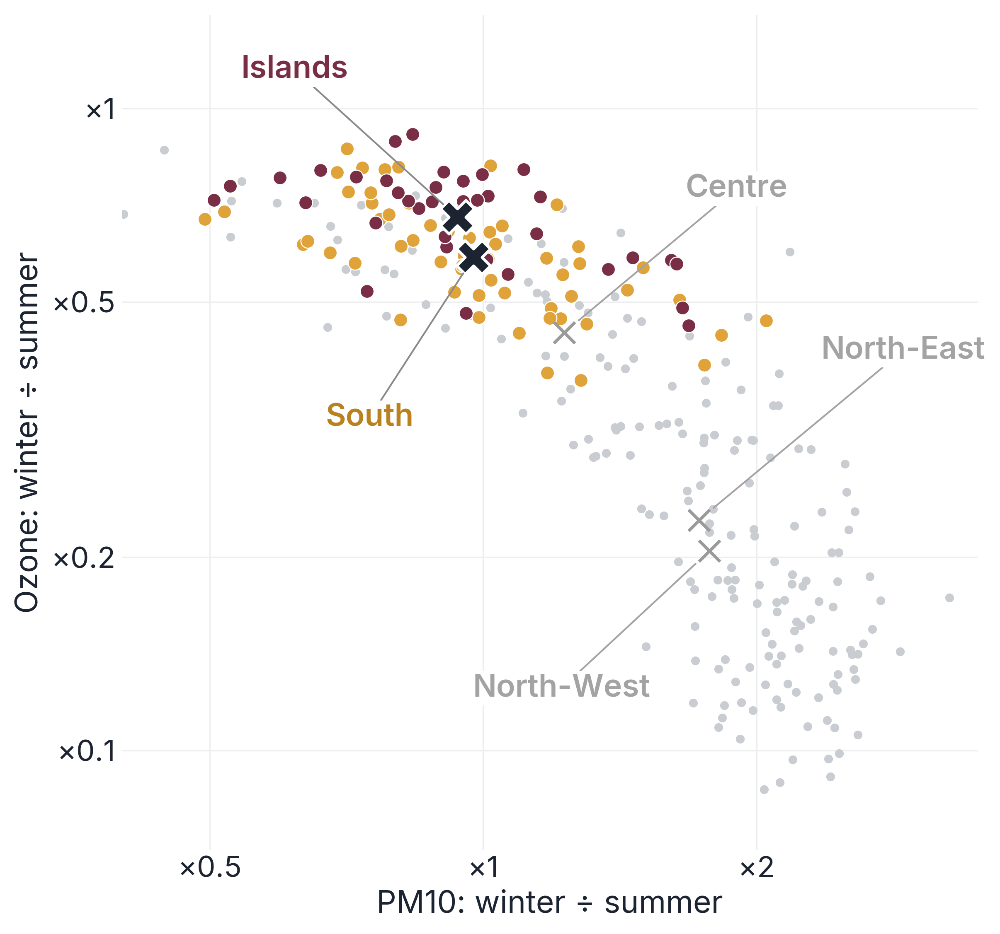

S04E_area_confusion.png


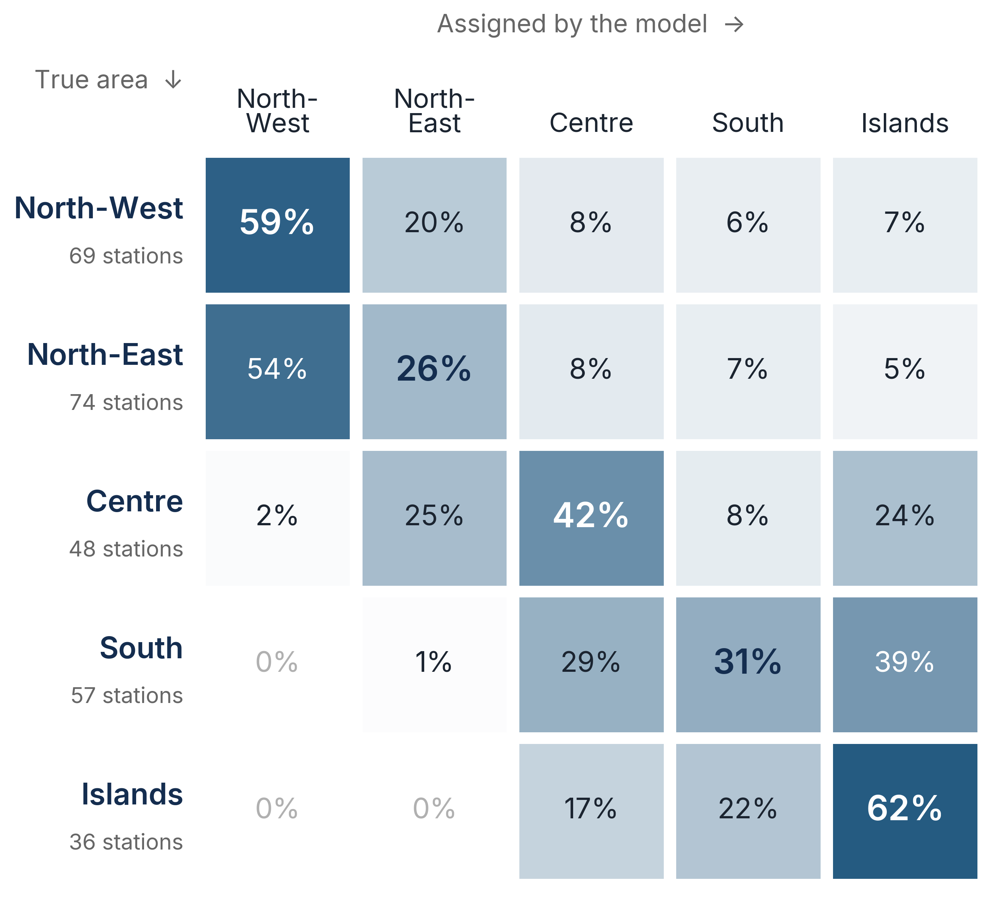

S04E2_stepA_three_zones.png


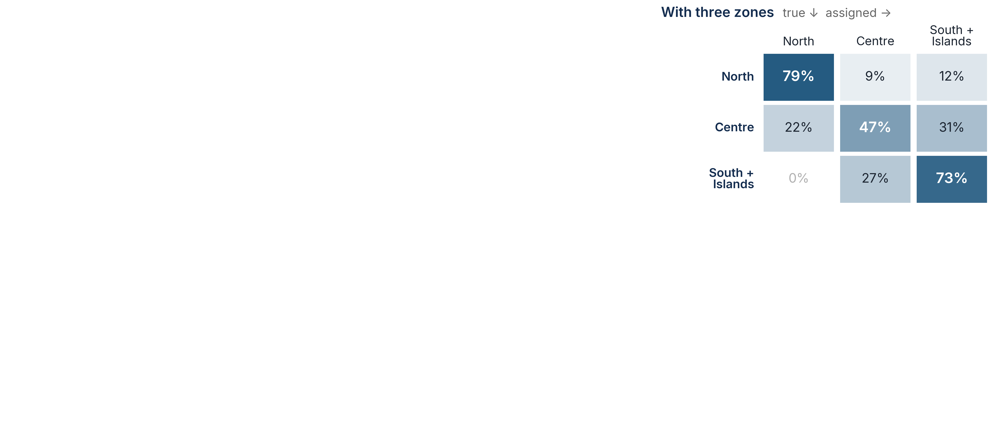

S04E2_stepB_altitude.png


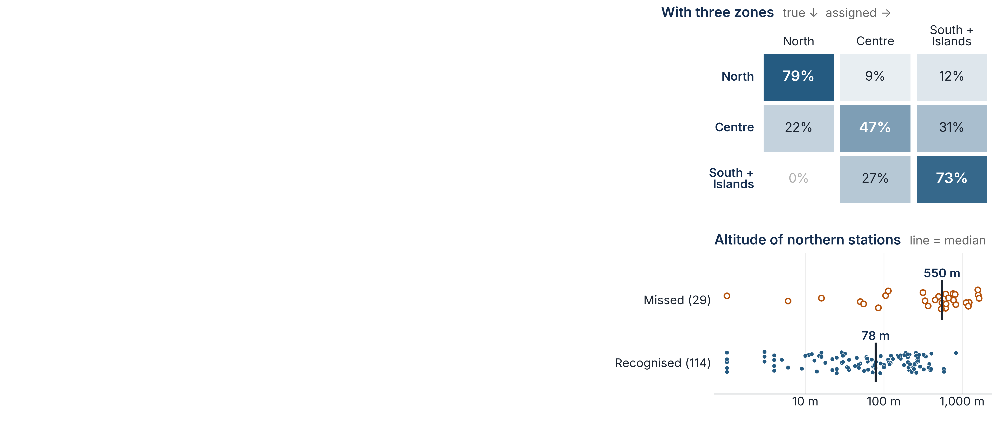

S04E2_stepC_map.png


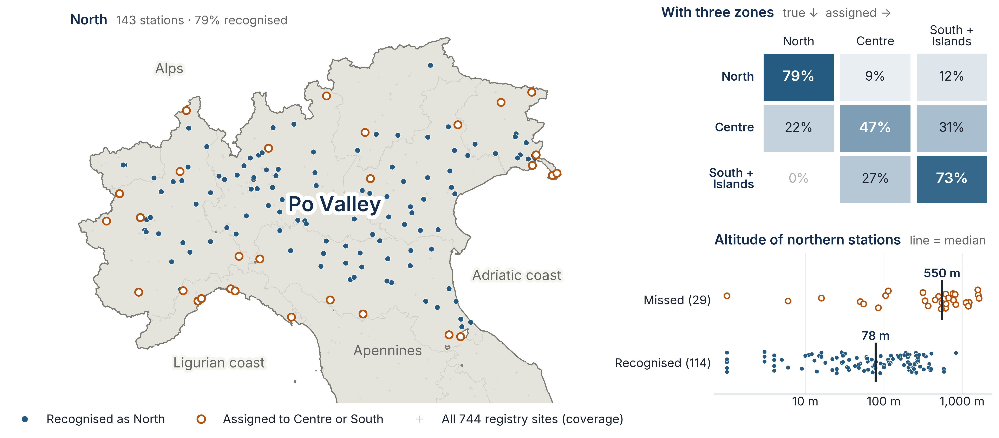

S04E2_map_unnamed.png


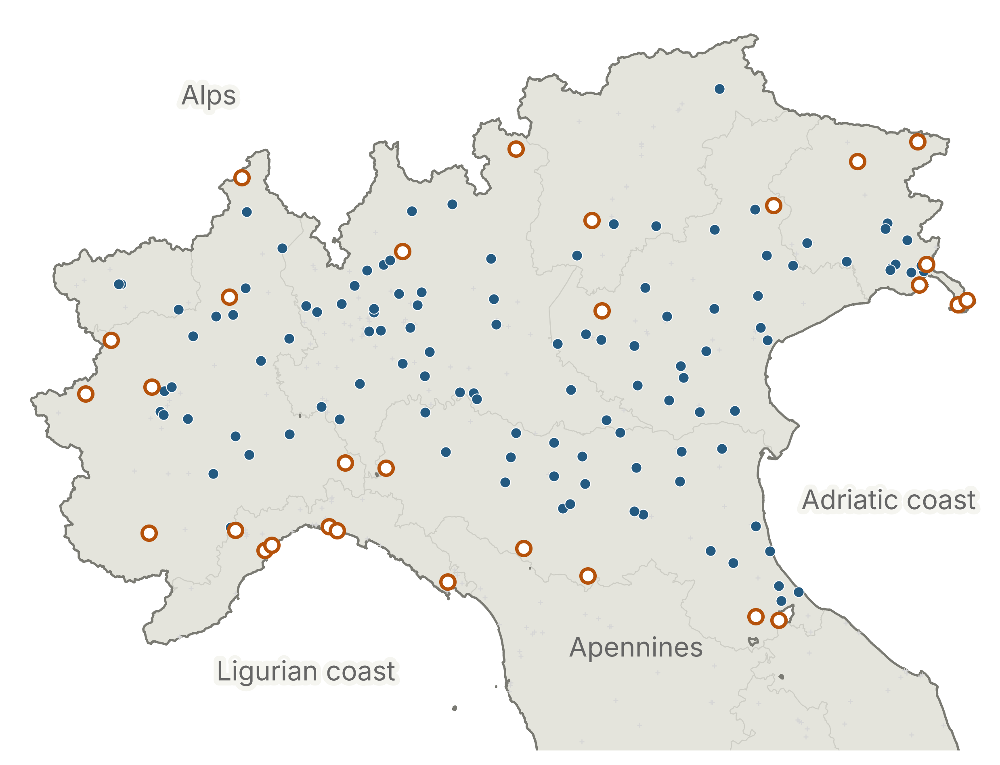

In [12]:
PAIR_COLOURS = {'North-West': '#1F4E79', 'North-East': '#6FA8DC', 'South': '#E0A33A', 'Islands': '#7A2E46'}


PAIR_TEXT = {**PAIR_COLOURS, 'South': '#B9821F'}


def place_ratio_axes(ax, first):
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(*PLACE_LIMITS[0])
    ax.set_ylim(*PLACE_LIMITS[1])
    ax.set_xticks([0.5, 1, 2], ['×0.5', '×1', '×2'])
    ax.set_yticks([0.1, 0.2, 0.5, 1], ['×0.1', '×0.2', '×0.5', '×1'] if first else [])
    ax.minorticks_off()
    ax.tick_params(length=0, labelsize=15, colors=INK)
    ax.grid(color='#ECEEF0', lw=0.8)
    ax.set_axisbelow(True)
    for side in ax.spines.values():
        side.set_visible(False)


def place_step(name, lit):
    monitors = fig_read('place_monitors.csv')
    metrics = fig_read('place_metrics.csv')
    centres = metrics.loc[metrics.grouping.eq('five areas') & metrics.measure.eq('centroid')].set_index('area')
    for area in AREAS:
        assert np.isclose(monitors.loc[monitors.area.eq(area), 'pm10_log_ratio'].mean(), centres.loc[area, 'pm10_log_ratio']), area
    fig = plt.figure(figsize=(8.6, 8.4))
    ax = fig.add_axes([0.16, 0.12, 0.8, 0.8])
    on = monitors.area.isin(lit)
    cloud = dict(s=40, color='#6F7780') if not lit else dict(s=26, color='#C9CDD2')
    ax.scatter(np.exp(monitors.pm10_log_ratio[~on]), np.exp(monitors.o3_log_ratio[~on]), lw=0, zorder=1, **cloud)
    for area in lit:
        part = monitors.loc[monitors.area.eq(area)]
        ax.scatter(np.exp(part.pm10_log_ratio), np.exp(part.o3_log_ratio), s=64, color=PAIR_COLOURS[area], edgecolor='white', lw=0.6, zorder=2)
    labels = {'North-West': (1.22, 0.125), 'North-East': (2.9, 0.42), 'Centre': (1.9, 0.75),
              'South': (0.75, 0.33), 'Islands': (0.62, 1.15)}
    for area, (tx, ty) in labels.items():
        x, y = np.exp(centres.loc[area, 'pm10_log_ratio']), np.exp(centres.loc[area, 'o3_log_ratio'])
        if not lit or area in lit:
            ax.scatter(x, y, s=380, marker='X', color=INK, edgecolor='white', lw=1.6, zorder=4)
        else:
            ax.scatter(x, y, s=150, marker='x', color='#9A9A9A', lw=1.8, zorder=4)
        faded = bool(lit) and area not in lit
        ax.annotate(area, (x, y), (tx, ty), ha='center', va='center', fontsize=18, weight='bold',
                    color=PAIR_TEXT[area] if area in lit else ('#A3A3A3' if faded else MUTED), bbox=dict(facecolor='white', edgecolor='none', pad=1.5),
                    arrowprops=dict(arrowstyle='-', color='#A3A3A3' if faded else '#8A8A8A', lw=1, shrinkA=0, shrinkB=11), zorder=5)
    place_ratio_axes(ax, True)
    ax.tick_params(labelsize=17)
    ax.set_xlabel('PM10: winter ÷ summer', fontsize=18)
    ax.set_ylabel('Ozone: winter ÷ summer', fontsize=18)
    save_figure(fig, name, '4E')


def place_steps():
    from PIL import Image
    frames = [('S04E_step1_model', []), ('S04E_step3_north', ['North-West', 'North-East']),
              ('S04E_step4_south', ['South', 'Islands'])]
    for name, lit in frames:
        place_step(name, lit)
    sizes = {Image.open(IMAGES / f'{name}.png').size for name, _ in frames}
    assert len(sizes) == 1, f'Build-up frames must overlay exactly: {sizes}'


def place_confusion():
    metrics = fig_read('place_metrics.csv')
    model = metrics.loc[metrics.grouping.eq('five areas') & metrics.model.eq('nearest centroid, 2 numbers')]
    share = model.loc[model.measure.eq('assigned share')].pivot(index='area', columns='assigned', values='value').loc[AREAS, AREAS]
    recall = model.loc[model.measure.eq('recall')].set_index('area').value.loc[AREAS]
    balanced = model.loc[model.measure.eq('balanced accuracy')].value.iloc[0]
    assert np.allclose(share.sum(axis=1), 1) and np.allclose(np.diag(share), recall)
    assert np.isclose(np.diag(share).mean(), balanced) and abs(balanced - 0.44) < 0.01
    counts = fig_read('place_monitors.csv').area.value_counts().reindex(AREAS)
    fig = plt.figure(figsize=(9.6, 8.4))
    ax = fig.add_axes([0.25, 0.04, 0.73, 0.78])
    cmap = LinearSegmentedColormap.from_list('share', ['#FFFFFF', ACCENT])
    short = {'North-West': 'North-\nWest', 'North-East': 'North-\nEast', 'Centre': 'Centre', 'South': 'South', 'Islands': 'Islands'}
    for i, true in enumerate(AREAS):
        for j, assigned in enumerate(AREAS):
            value = 100 * share.loc[true, assigned]
            ax.add_patch(Rectangle((j + 0.04, i + 0.04), 0.92, 0.92, facecolor=cmap(min(value, 62) / 62), edgecolor='none'))
            ax.text(j + 0.5, i + 0.5, f'{round(value)}%', ha='center', va='center', fontsize=22 if i == j else 18,
                    weight='bold' if i == j else 'normal', color='white' if value > 36 else INK if value >= 1 else '#B0B0B0')
        ax.text(-0.1, i + 0.4, true, ha='right', va='center', fontsize=19, weight='bold', color=INK)
        ax.text(-0.1, i + 0.72, f'{counts[true]} stations', ha='right', va='center', fontsize=MIN_FONT, color=MUTED)
    for j, assigned in enumerate(AREAS):
        ax.text(j + 0.5, -0.1, short[assigned], ha='center', va='bottom', fontsize=17, color=INK, linespacing=1.0)
    ax.text(2.5, -0.78, 'Assigned by the model  →', ha='center', va='bottom', fontsize=16, color=MUTED)
    ax.text(-0.1, -0.4, 'True area  ↓', ha='right', va='bottom', fontsize=16, color=MUTED)
    ax.set_xlim(-0.02, 5.02)
    ax.set_ylim(5.02, -0.02)
    ax.axis('off')
    save_figure(fig, 'S04E_area_confusion', '4E')


def north_po_valley_frame(show, po_label=True, legend=True, title=True):
    from matplotlib import patheffects
    from matplotlib.lines import Line2D
    monitors = fig_read('place_monitors.csv')
    metrics = fig_read('place_metrics.csv')
    sites = fig_read('registry')
    north = monitors.loc[monitors.area3.eq('North')]
    recall = metrics.query("grouping == 'three areas' and measure == 'recall'").set_index('area').value
    alt = metrics.loc[metrics.measure.str.startswith('North ')].set_index('measure')
    assert len(north) == 143 and north.recognised_three.sum() == 114
    fig = frame()
    fig.set_size_inches(16, 7.6)
    ok = north.recognised_three.to_numpy(bool)
    if 'map' in show:
        ax = fig.add_axes([0.0, 0.08, 0.6, 0.8])
        import json
        from collections import Counter
        from matplotlib.collections import LineCollection
        LAND, SLIDE = '#E4E4DC', '#F5F5F0'
        geo = json.loads((PACKAGE / 'assets/limits_IT_regions.geojson').read_text())
        edges = Counter()
        for feature in geo['features']:
            shape = feature['geometry']
            parts = [shape['coordinates']] if shape['type'] == 'Polygon' else shape['coordinates']
            for part in parts:
                ax.add_patch(Polygon(part[0], closed=True, facecolor=LAND, edgecolor='#CDCDC5', lw=0.6, zorder=0))
                ring = [tuple(round(v, 6) for v in point) for point in part[0]]
                edges.update(frozenset(pair) for pair in zip(ring, ring[1:]) if pair[0] != pair[1])
        outline = [tuple(edge) for edge, count in edges.items() if count == 1]
        ax.add_collection(LineCollection(outline, colors='#7A7A73', lw=1.3, zorder=0.5, capstyle='round'))
        ax.scatter(sites.Longitude, sites.Latitude, s=9, color='#d6d6d6', marker='+', lw=0.6, zorder=1)
        ax.scatter(north.longitude[ok], north.latitude[ok], s=40, color=ACCENT, edgecolor='white', lw=0.5, zorder=3)
        ax.scatter(north.longitude[~ok], north.latitude[~ok], s=70, facecolor='white', edgecolor=MISSED, lw=2, zorder=4)
        ax.set(xlim=(6.5, 14.0), ylim=(43.2, 47.2), aspect=1 / np.cos(np.deg2rad(45.3)), xticks=[], yticks=[])
        for side in ax.spines.values():
            side.set_visible(False)
        places = [('Po Valley', 10.5, 45.3), ('Alps', 8.0, 46.75), ('Ligurian coast', 8.75, 43.62), ('Apennines', 11.3, 43.75), ('Adriatic coast', 13.25, 44.55)]
        for text, lon, lat in places[0 if po_label else 1:]:
            po = text == 'Po Valley'
            halo = 'white' if po else SLIDE if text in ('Alps', 'Ligurian coast', 'Adriatic coast') else LAND
            ax.text(lon, lat, text, fontsize=24 if po else 16, weight='bold' if po else 'normal', color=INK if po else MUTED, style='italic',
                    ha='center', va='center', zorder=6, path_effects=[patheffects.withStroke(linewidth=9 if po else 6, foreground=halo)])
        if title:
            heading(ax, 'North', f"{len(north)} stations · {recall['North'] * 100:.0f}% recognised", anchor=(0, 1.0), detail_size=MIN_FONT)
        if legend:
            ax.legend([Line2D([], [], marker='o', ls='', color=ACCENT, mec='white', ms=8), Line2D([], [], marker='o', ls='', mfc='white', mec=MISSED, mew=2, ms=9), Line2D([], [], marker='+', ls='', color='#bdbdbd', ms=8, mew=1)], ['Recognised as North', 'Assigned to Centre or South', 'All 744 registry sites (coverage)'], loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False, fontsize=14)
    if 'matrix' in show:
        zones = ['North', 'Centre', 'South and Islands']
        share = monitors.groupby('area3')[[f'three_share_{z}' for z in zones]].mean().loc[zones]
        assert np.allclose(np.diag(share), recall.loc[zones]) and np.allclose(share.sum(axis=1), 1)
        bx = fig.add_axes([0.745, 0.5, 0.235, 0.33])
        cmap = LinearSegmentedColormap.from_list('share', ['#FFFFFF', ACCENT])
        short = {'North': 'North', 'Centre': 'Centre', 'South and Islands': 'South +\nIslands'}
        for i, true in enumerate(zones):
            for j, assigned in enumerate(zones):
                value = 100 * share.loc[true, f'three_share_{assigned}']
                bx.add_patch(Rectangle((j + 0.04, i + 0.04), 0.92, 0.92, facecolor=cmap(min(value, 80) / 80), edgecolor='none'))
                bx.text(j + 0.5, i + 0.5, f'{round(value)}%', ha='center', va='center', fontsize=17 if i == j else 15,
                        weight='bold' if i == j else 'normal', color='white' if value > 45 else INK if value >= 1 else '#B0B0B0')
            bx.text(-0.08, i + 0.5, short[true], ha='right', va='center', fontsize=14, weight='bold', color=INK, linespacing=1.0)
            bx.text(i + 0.5, -0.08, short[true], ha='center', va='bottom', fontsize=14, color=INK, linespacing=1.0)
        bx.set_xlim(-0.02, 3.02)
        bx.set_ylim(3.02, -0.02)
        bx.axis('off')
        heading(bx, 'With three zones', 'true ↓  assigned →', anchor=(-0.42, 1.2), detail_size=MIN_FONT)
    if 'altitude' in show:
        cx = fig.add_axes([0.7, 0.1, 0.28, 0.3])
        rng = np.random.default_rng(1)
        for i, flag in enumerate([True, False]):
            a = north.altitude[north.recognised_three.eq(flag)].clip(lower=1)
            yj = i + rng.uniform(-0.17, 0.17, len(a))
            if flag:
                cx.scatter(a, yj, s=24, color=ACCENT, edgecolor='white', lw=0.4)
            else:
                cx.scatter(a, yj, s=40, facecolor='white', edgecolor=MISSED, lw=1.6)
            median = alt.loc[f"North {('recognised' if flag else 'missed')}: median altitude", 'value']
            assert abs(median - a.median()) < 1e-09
            cx.plot([median, median], [i - 0.3, i + 0.3], color=INK, lw=2.4, zorder=5)
            cx.text(median, i + 0.36, f'{median:.0f} m', ha='center', fontsize=14, color=INK, weight='bold')
        cx.set_xscale('log')
        cx.set_xticks([10, 100, 1000], ['10 m', '100 m', '1,000 m'])
        cx.minorticks_off()
        cx.set_yticks([0, 1], [f'Recognised ({ok.sum()})', f'Missed ({(~ok).sum()})'])
        cx.set_ylim(-0.5, 1.75)
        cx.tick_params(length=0, labelsize=14)
        cx.grid(axis='x', color='#ededed')
        cx.set_axisbelow(True)
        for side in ('top', 'right', 'left'):
            cx.spines[side].set_visible(False)
        heading(cx, 'Altitude of northern stations', 'line = median', anchor=(0, 1.04), detail_size=MIN_FONT)
    return fig


def north_po_valley():
    from PIL import Image
    frames = [('S04E2_stepA_three_zones', ('matrix',), True), ('S04E2_stepB_altitude', ('matrix', 'altitude'), True),
              ('S04E2_stepC_map', ('matrix', 'altitude', 'map'), True)]
    full = north_po_valley_frame(frames[-1][1])
    style_text(full)
    from matplotlib.transforms import Bbox
    tight = full.get_tightbbox(full.canvas.get_renderer())
    bbox = Bbox.from_extents(tight.x0 - .12, tight.y0 - .12, tight.x1 + .12, tight.y1 + .12)
    plt.close(full)
    for name, show, po_label in frames:
        save_figure(north_po_valley_frame(show, po_label), name, '4E2', bbox=bbox)
    sizes = {Image.open(IMAGES / f'{name}.png').size for name, _, _ in frames}
    assert len(sizes) == 1, f'Build-up frames must overlay exactly: {sizes}'
    save_figure(north_po_valley_frame(('map',), po_label=False, legend=False, title=False), 'S04E2_map_unnamed', '4E2')


place_steps()
place_confusion()
north_po_valley()

## 6. Decade change

In [13]:
DECADE_POLLUTANTS = CORE + ['SO2', 'CO']
DRAW_ORDER = ['NO2', 'CO', 'PM10', 'PM2.5', 'SO2', 'O3']


def block_means(frame, minimum):
    columns = {}
    for block, years in BLOCKS.items():
        selected = frame[frame.year.isin(years)]
        grouped = selected.groupby(['pollutant', 'AirQualityStation'])
        counts = grouped.size()
        columns[block] = grouped['mean'].mean().where(counts.ge(minimum))
        columns[f'{block}_support'] = counts
    result = pd.DataFrame(columns).dropna(subset=['early', 'late']).reset_index()
    result['change_percent'] = 100 * (result.late / result.early - 1)
    return result


def annual_changes():
    annual = pd.read_csv(TABLES / 'common_annual.csv')
    eligible = annual.merge(eligible_years(), on=['AirQualityStation', 'year', 'pollutant'])
    eligible = eligible[eligible.pollutant.isin(DECADE_POLLUTANTS)]
    changes = block_means(eligible, 2)
    meta = registry()[['AirQualityStation', 'Longitude', 'Latitude', 'area3']].rename(columns={'area3': 'area'})
    return changes.merge(meta, on='AirQualityStation', validate='many_to_one')


def seasonal_months():
    months = monthly(eligible=True)
    pieces = []
    for pollutant in DECADE_POLLUTANTS:
        stations = strict_annual_sample(pollutant).AirQualityStation.unique()
        pieces.append(months[months.pollutant.eq(pollutant) & months.AirQualityStation.isin(stations)])
    result = pd.concat(pieces, ignore_index=True)
    result = pd.read_csv(StringIO(result.to_csv(index=False)))
    result['season'] = result.month.map({month: season for season, months in SEASONS.items() for month in months})
    return result


def seasonal_changes(months):
    pieces = []
    for season, selected in months.groupby('season'):
        changed = block_means(selected, 4).rename(columns={'early_support': 'early_months', 'late_support': 'late_months'})
        changed['season'] = season
        pieces.append(changed)
    result = pd.concat(pieces, ignore_index=True)
    meta = registry()[['AirQualityStation', 'area3']].rename(columns={'area3': 'area'})
    return result.merge(meta, on='AirQualityStation', validate='many_to_one').sort_values(
        ['pollutant', 'season', 'AirQualityStation']).reset_index(drop=True)


def decade_precision(blocks):
    rng = np.random.default_rng(20261107)
    rows, points = [], []
    for pollutant in DRAW_ORDER:
        selected = blocks[blocks.pollutant.eq(pollutant)]
        values = selected.change_percent.to_numpy()
        low, high = bootstrap_median(values, rng)
        inside = selected[selected.change_percent.abs().le(80)]
        values_inside = inside.change_percent.to_numpy()
        density = stats.gaussian_kde(values_inside)(values_inside)
        density = density / density.max()
        jitter = rng.uniform(-1, 1, len(inside)) * .34 * density
        rows.append({'pollutant': pollutant, 'monitors': len(values), 'median': float(np.median(values)),
                     'low': low, 'high': high, 'beyond_display': int((np.abs(values) > 80).sum())})
        points.append(inside[['pollutant', 'AirQualityStation', 'change_percent']].assign(jitter=jitter))
    return pd.DataFrame(rows), pd.concat(points, ignore_index=True)


def seasonal_precision(changes):
    rng = np.random.default_rng(20261107)
    rows = []
    for pollutant in DRAW_ORDER:
        for season in SEASON_ORDER:
            selected = changes[changes.pollutant.eq(pollutant) & changes.season.eq(season)]
            values = selected.change_percent.to_numpy()
            low, high = bootstrap_median(values, rng)
            rows.append({'pollutant': pollutant, 'season': season, 'monitors': len(values),
                         'median': float(np.median(values)), 'low': low, 'high': high,
                         'excludes_zero': bool(high < 0 or low > 0)})
    return pd.DataFrame(rows)


save(annual_changes(), 'decade_blocks.csv')
blocks = pd.read_csv(TABLES / 'decade_blocks.csv')
precision, points = decade_precision(blocks)
save(precision, 'decade_summary.csv')
save(points, 'decade_points.csv')
months = seasonal_months()
save(seasonal_changes(months), 'decade_seasons.csv')
seasonal = pd.read_csv(TABLES / 'decade_seasons.csv')
save(seasonal_precision(seasonal), 'decade_season_summary.csv');

decade_blocks.csv: 962 rows


decade_summary.csv: 6 rows


decade_points.csv: 951 rows


decade_seasons.csv: 3,716 rows


decade_season_summary.csv: 24 rows


**Decade.** 2021–23 against 2013–15 at the same stations, overall and by season.

S08_decade_change.png


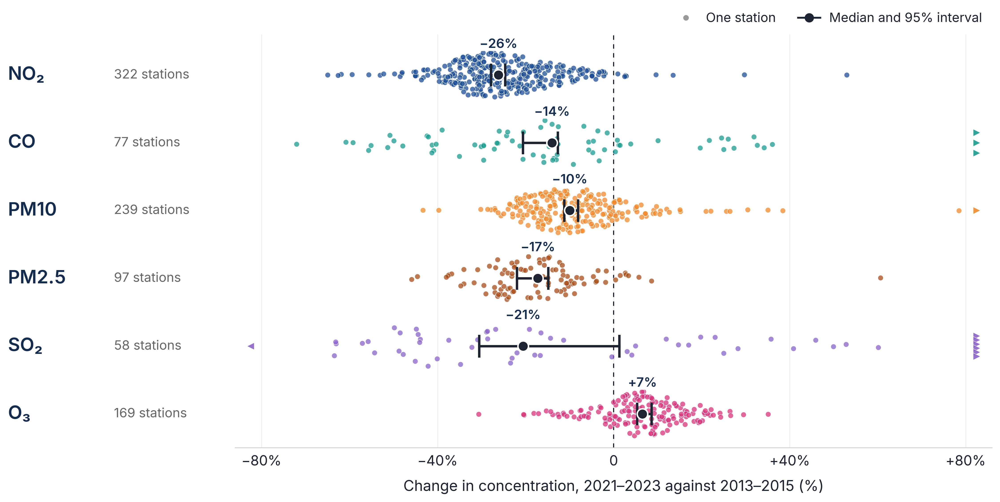

S08A_seasonal_change.png


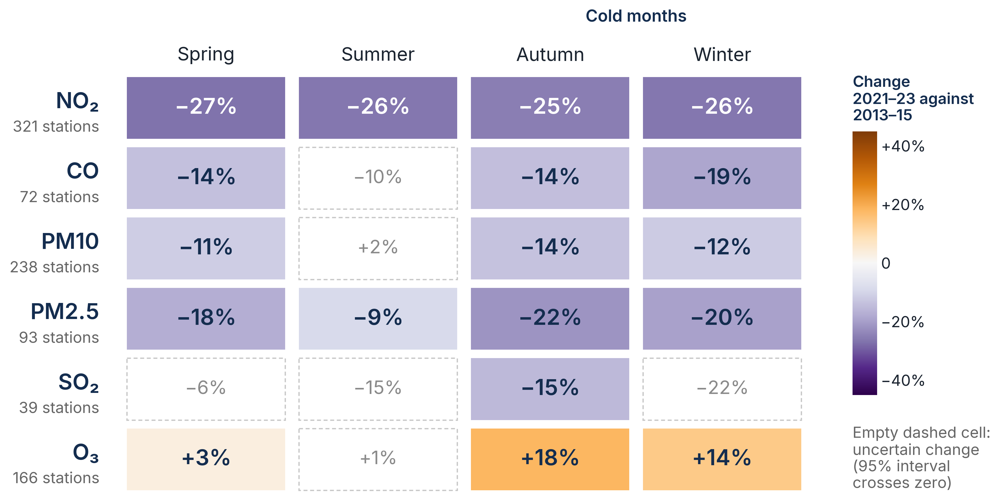

In [14]:
def decade_blocks():
    return fig_read('decade_blocks.csv')


def decade_change():
    blocks = decade_blocks()
    summary = fig_read('decade_summary.csv').set_index('pollutant')
    points = fig_read('decade_points.csv')
    order = ['NO2', 'CO', 'PM10', 'PM2.5', 'SO2', 'O3']
    expected = {'NO2': 322, 'PM10': 239, 'PM2.5': 97, 'O3': 169, 'SO2': 58, 'CO': 77}
    medians = {'NO2': -26, 'PM10': -10, 'PM2.5': -17, 'O3': 7, 'SO2': -21, 'CO': -14}
    fig = frame()
    fig.set_size_inches(16, 8.4)
    ax = fig.add_axes([0.25, 0.14, 0.71, 0.74])
    limit = 80
    for y, pollutant in enumerate(order):
        values = blocks.loc[blocks.pollutant.eq(pollutant), 'change_percent'].to_numpy()
        if pollutant in expected:
            assert len(values) == expected[pollutant]
        median = float(summary.loc[pollutant, 'median'])
        assert abs(median - medians[pollutant]) < 0.6
        lo, hi = summary.loc[pollutant, ['low', 'high']]
        inside = values[np.abs(values) <= limit]
        jitter = points.loc[points.pollutant.eq(pollutant), 'jitter'].to_numpy()
        ax.scatter(inside, y + jitter, s=34, color=to_rgba(COLOURS[pollutant], 0.75), edgecolor='white', lw=0.4, zorder=2)
        for side, marker in ((1, '>'), (-1, '<')):
            far = values[side * values > limit]
            for k, offset in enumerate(np.linspace(-0.15, 0.15, len(far)) if len(far) > 1 else [0.0] * len(far)):
                ax.scatter([side * (limit + 2.5)], [y + offset], marker=marker, s=60, color=to_rgba(COLOURS[pollutant], 0.9), edgecolor='white', lw=0.4, zorder=3)
        ax.plot([lo, hi], [y, y], color=INK, lw=2.6, zorder=4)
        for x in (lo, hi):
            ax.plot([x, x], [y - 0.15, y + 0.15], color=INK, lw=2.6, zorder=4)
        ax.scatter([median], [y], s=130, color=INK, edgecolor='white', lw=1.6, zorder=5)
        label = f'{medians[pollutant]:+d}%'.replace('-', '−')
        ax.text(median, y - 0.36, label, ha='center', va='bottom', fontsize=14, weight='bold', color=INK, zorder=6, bbox=dict(facecolor='white', edgecolor='none', pad=0.4))
        ax.text(-0.3, y, NAMES[pollutant], transform=ax.get_yaxis_transform(), fontsize=20, weight='bold', va='center', color=INK)
        detail = f'{len(values)} stations' if pollutant in expected else 'sample: check F1'
        ax.text(-0.16, y, detail, transform=ax.get_yaxis_transform(), fontsize=12, va='center', color=MUTED)
    ax.axvline(0, color=INK, lw=1.2, ls=(0, (4, 4)), zorder=1)
    ax.set(xlim=(-limit - 6, limit + 6), ylim=(len(order) - 0.5, -0.6), yticks=[], xticks=[-80, -40, 0, 40, 80])
    ax.set_xticklabels(['−80%', '−40%', '0', '+40%', '+80%'])
    ax.tick_params(axis='x', labelsize=15, length=0, pad=8)
    ax.grid(axis='x', color='#ededed', lw=0.8)
    ax.set_axisbelow(True)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_color('#cccccc')
    ax.set_xlabel('Change in concentration, 2021–2023 against 2013–2015 (%)', fontsize=16, labelpad=12)
    from matplotlib.lines import Line2D
    ax.legend([Line2D([], [], marker='o', ls='', ms=5, color='#999999'), Line2D([], [], marker='o', ls='-', ms=9, color=INK, lw=2)], ['One station', 'Median and 95% interval'], loc='lower right', bbox_to_anchor=(1, 1.0), ncol=2, frameon=False, fontsize=12)
    save_figure(fig, 'S08_decade_change', '8')


def season_heatmap(cells, monitors, key_title, empty_text, check_kind):
    fig = plt.gcf()
    cmap, norm = (plt.get_cmap('PuOr_r'), TwoSlopeNorm(0, -45, 45))
    fmt = lambda v: f'{round(v):+d}%'.replace('-', '−')
    ax = fig.add_axes([0.2, 0.08, 0.62, 0.72])
    for i, pollutant in enumerate(HEATMAP_ORDER):
        for j, season in enumerate(SEASON_ORDER):
            value, low, high, clear = cells[pollutant, season]
            if clear:
                assert not low < 0 < high, (pollutant, season)
            ax.add_patch(Rectangle((j + 0.04, i + 0.06), 0.92, 0.88, facecolor=cmap(norm(value)) if clear else 'none', edgecolor='none' if clear else '#C9C9C9', lw=1.2, ls=(0, (3, 2))))
            dark = clear and abs(value) > 22
            ax.text(j + 0.5, i + 0.5, fmt(value), ha='center', va='center', fontsize=20 if clear else 17, weight='bold' if clear else 'normal', color='white' if dark else INK if clear else '#8A8A8A')
        ax.text(-0.12, i + 0.42, NAMES[pollutant], ha='right', va='center', fontsize=20, weight='bold', color=INK)
        ax.text(-0.12, i + 0.78, f'{monitors[pollutant]} stations', ha='right', va='center', fontsize=MIN_FONT, color=MUTED)
    ax.set_xlim(0, 4)
    ax.set_ylim(len(HEATMAP_ORDER), 0)
    ax.axis('off')
    for j, season in enumerate(SEASON_ORDER):
        ax.text(j + 0.5, -0.12, season.capitalize(), ha='center', va='bottom', fontsize=17, color=INK)
    ax.plot([2.06, 3.94], [-0.62, -0.62], color=INK, lw=1.4)
    ax.text(3, -0.68, 'Cold months', ha='center', va='bottom', fontsize=15, color=INK, weight='bold')
    key = fig.add_axes([0.86, 0.25, 0.022, 0.45])
    bar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=key)
    bar.set_ticks([-40, -20, 0, 20, 40])
    bar.set_ticklabels(['−40%', '−20%', '0', '+20%', '+40%'])
    bar.outline.set_visible(False)
    key.tick_params(labelsize=MIN_FONT, length=0)
    key.set_title(key_title, fontsize=MIN_FONT, color=INK, loc='left', pad=10)
    key.text(0, -0.12, empty_text, transform=key.transAxes, fontsize=MIN_FONT, color=MUTED, va='top')


def seasonal_change_bars():
    summary = fig_read('decade_season_summary.csv').set_index(['pollutant', 'season'])
    cells, monitors = ({}, {})
    for pollutant in HEATMAP_ORDER:
        for season in SEASON_ORDER:
            row = summary.loc[pollutant, season]
            cells[pollutant, season] = (row['median'], row.low, row.high, bool(row.excludes_zero))
        monitors[pollutant] = int(summary.loc[(pollutant, 'winter'), 'monitors'])
    fig = frame()
    fig.set_size_inches(14, 7.4)
    season_heatmap(cells, monitors, 'Change\n2021–23 against\n2013–15', 'Empty dashed cell:\nuncertain change\n(95% interval\ncrosses zero)', 'block')
    save_figure(fig, 'S08A_seasonal_change', '8A')


decade_change()
seasonal_change_bars()

## 7. Weather normalisation

Method: Grange, S. K., Carslaw, D. C., Lewis, A. C., Boleti, E., Hueglin, C. (2018). Random forest meteorological normalisation models for Swiss PM₁₀ trend analysis. *Atmospheric Chemistry and Physics*, 18, 6223–6239. https://doi.org/10.5194/acp-18-6223-2018

In [15]:
WEATHER_POLLUTANTS = ['NO2', 'PM10', 'PM2.5', 'O3', 'CO', 'SO2']
WEATHER_ORDER = ['NO2', 'PM2.5', 'CO', 'PM10', 'SO2', 'O3']
WEATHER = ['CL_t2m', 'CL_tp', 'CL_windspeed', 'CL_winddir', 'CL_blh', 'CL_rh', 'CL_ssr']


FEATURES = ['trend', 'doy', 'wday'] + WEATHER


DRAWS = 40


def load_weather_daily(raw, cache):
    if cache and Path(cache).exists():
        return pd.read_pickle(cache)
    columns = ['AirQualityStation', 'time'] + ['AQ_mean_' + p for p in WEATHER_POLLUTANTS] + WEATHER
    files = sorted(Path(raw).glob('GRINS_AQCLIM_points_Italy_y*.csv'))
    assert len(files) == 6, 'expected the six GRINS point partitions'
    frame = pd.concat([pd.read_csv(f, usecols=columns, parse_dates=['time']) for f in files], ignore_index=True)
    if cache:
        frame.to_pickle(cache)
    return frame


def normalised_mean(model, pool, days, rng):
    rows = pool[rng.integers(0, len(pool), size=len(days) * DRAWS)].copy()
    rows[:, 0] = np.repeat(days[:, 0], DRAWS)
    return float(model.predict(rows).mean())


def fit_station(pollutant, name, frame, seed):
    target = 'AQ_mean_' + pollutant
    valid = frame[frame[target].notna() & frame[WEATHER].notna().all(axis=1)]
    if len(valid) < MIN_TRAIN:
        return None
    X, y = valid[FEATURES].to_numpy(float), valid[target].to_numpy(float)
    forest = RandomForestRegressor(n_estimators=300, max_features=3, min_samples_leaf=5, oob_score=True,
                                   random_state=seed, n_jobs=1).fit(X, y)
    boost = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=seed).fit(X, y)
    model_row = {'pollutant': pollutant, 'AirQualityStation': name, 'train_days': len(valid),
                 'oob_r2': forest.oob_score_, **dict(zip(FEATURES, forest.feature_importances_))}
    periods = {'year': valid.time.dt.month.between(1, 12)}
    periods.update({season: valid.time.dt.month.isin(months) for season, months in SEASONS.items()})
    rng = np.random.default_rng(seed)
    rows = []
    for period, in_period in periods.items():
        pool = X[in_period.to_numpy()]
        minimum = MIN_BLOCK if period == 'year' else MIN_SEASON_BLOCK
        for block, (first, last) in WEATHER_BLOCKS.items():
            chosen = (in_period & valid.time.dt.year.between(first, last)).to_numpy()
            if chosen.sum() < minimum:
                continue
            state = rng.bit_generator.state
            forest_mean = normalised_mean(forest, pool, X[chosen], rng)
            rng.bit_generator.state = state
            boost_mean = normalised_mean(boost, pool, X[chosen], rng)
            rows.append({'pollutant': pollutant, 'AirQualityStation': name, 'period': period, 'block': block,
                         'days': int(chosen.sum()), 'observed': float(y[chosen].mean()),
                         'forest': forest_mean, 'boosting': boost_mean})
    return rows, model_row
WEATHER_BLOCKS = {'early': (2013, 2015), 'late': (2021, 2023)}
MIN_TRAIN, MIN_BLOCK, MIN_SEASON_BLOCK = 500, 300, 90


weather_daily = load_weather_daily(RAW, None)
weather_daily['trend'] = (weather_daily.time - pd.Timestamp('2013-01-01')).dt.days
weather_daily['doy'], weather_daily['wday'] = weather_daily.time.dt.dayofyear, weather_daily.time.dt.dayofweek
jobs = list(pd.read_csv(TABLES / 'decade_blocks.csv')[['pollutant', 'AirQualityStation']].itertuples(index=False))
groups = dict(tuple(weather_daily.groupby('AirQualityStation')))
results = Parallel(n_jobs=-1)(delayed(fit_station)(p, s, groups[s], 20261111 + i) for i, (p, s) in enumerate(jobs))
results = [r for r in results if r]
pd.DataFrame([row for rows, _ in results for row in rows]).to_csv(TABLES / 'deweather_station.csv', index=False)
pd.DataFrame([model for _, model in results]).to_csv(TABLES / 'deweather_models.csv', index=False)

In [16]:
ORDER = WEATHER_ORDER
def interval(values, rng):
    values = np.asarray(values, float)
    draws = np.median(rng.choice(values, size=(4000, len(values)), replace=True), axis=1)
    low, high = np.percentile(draws, [2.5, 97.5])
    return float(np.median(values)), float(low), float(high)


def deweather_changes(stations):
    wide = stations.pivot_table(index=['pollutant', 'AirQualityStation', 'period'], columns='block',
                                values=['observed', 'forest', 'boosting']).dropna()
    wide.columns = [f'{measure}_{block}' for measure, block in wide.columns]
    wide = wide.reset_index()
    for measure in ('observed', 'forest', 'boosting'):
        wide[f'{measure}_change'] = 100 * (wide[f'{measure}_late'] / wide[f'{measure}_early'] - 1)
    wide['weather_points'] = wide.observed_change - wide.forest_change
    return wide


def summarise_weather(frame, package, keys):
    rng = np.random.default_rng(20261107)
    rows = []
    for key, group in frame.groupby(keys, sort=False):
        key = key if isinstance(key, tuple) else (key,)
        row = dict(zip(keys, key), stations=len(group))
        for measure in ('package', 'observed', 'forest', 'boosting'):
            column = 'change_percent' if measure == 'package' else f'{measure}_change'
            row[measure], row[f'{measure}_low'], row[f'{measure}_high'] = interval(group[column], rng)
        for measure in ('observed', 'forest'):
            for block in ('early', 'late'):
                row[f'{measure}_{block}_level'] = float(group[f'{measure}_{block}'].median())
            row[f'{measure}_absolute'] = float((group[f'{measure}_late'] - group[f'{measure}_early']).median())
        row['weather_points'] = float(group.weather_points.median())
        row['forest_excludes_zero'] = row['forest_low'] > 0 or row['forest_high'] < 0
        rows.append(row)
    result = pd.DataFrame(rows)
    return result.merge(package, on=keys, how='left')


def weather_blocks(frame, sample):
    frame = frame[frame.AirQualityStation.isin(sample.AirQualityStation.unique())].copy()
    frame['block'] = np.select([frame.time.dt.year.between(2013, 2015), frame.time.dt.year.between(2021, 2023)],
                               ['early', 'late'], '')
    frame = frame[frame.block.ne('')]
    frame['season'] = frame.time.dt.month.map({m: s for s, ms in SEASONS.items() for m in ms})
    frame['CL_tp'] = 1000 * frame.CL_tp
    frame['CL_ssr'] = frame.CL_ssr / 1e6
    variables = ['CL_t2m', 'CL_ssr', 'CL_blh', 'CL_windspeed', 'CL_tp', 'CL_rh']
    rows = []
    for pollutant in ORDER:
        stations = sample[sample.pollutant.eq(pollutant)].AirQualityStation.unique()
        part = frame[frame.AirQualityStation.isin(stations)]
        for period, selected in [('year', part)] + list(part.groupby('season')):
            means = selected.groupby(['AirQualityStation', 'block'])[variables].mean().unstack('block')
            row = {'pollutant': pollutant, 'period': period}
            for variable in variables:
                row[variable] = float((means[(variable, 'late')] - means[(variable, 'early')]).median())
            rows.append(row)
    return pd.DataFrame(rows)


table = deweather_changes(pd.read_csv(TABLES / 'deweather_station.csv'))
blocks = pd.read_csv(TABLES / 'decade_blocks.csv')[['pollutant', 'AirQualityStation', 'change_percent']]
year = table[table.period.eq('year')].merge(blocks, on=['pollutant', 'AirQualityStation'], validate='one_to_one')
package = pd.read_csv(TABLES / 'decade_summary.csv')[['pollutant', 'monitors', 'median']].rename(
    columns={'monitors': 'slide_stations', 'median': 'slide_median'})
weather_summary = summarise_weather(year, package, ['pollutant']).set_index('pollutant').loc[WEATHER_ORDER].reset_index()
weather_summary.to_csv(TABLES / 'deweather_summary.csv', index=False)
weather_blocks(weather_daily, year).to_csv(TABLES / 'weather_blocks.csv', index=False)
del weather_daily, groups

**Weather.** The decade change as measured and under typical weather.

S08B_decade_weather.png


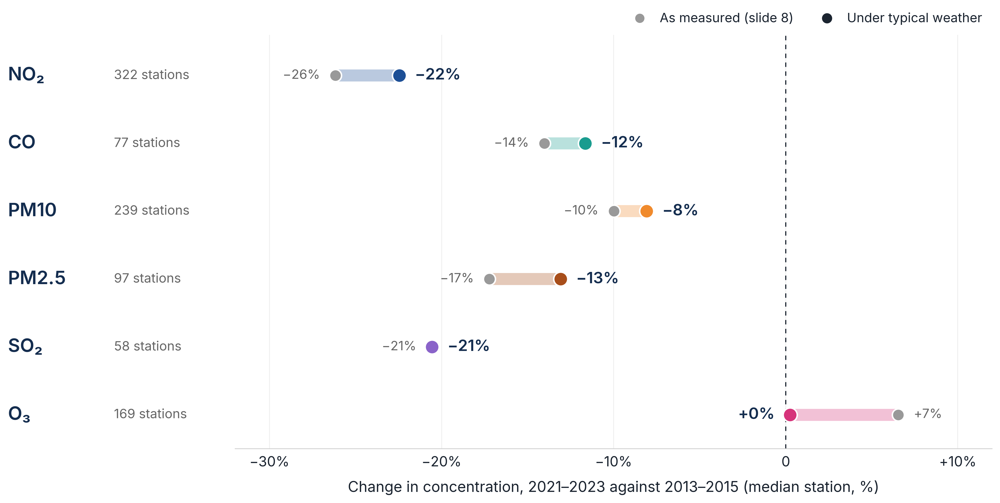

In [17]:
def decade_weather():
    from matplotlib.lines import Line2D
    table = pd.read_csv(TABLES / 'deweather_summary.csv').set_index('pollutant')
    order = ['NO2', 'CO', 'PM10', 'PM2.5', 'SO2', 'O3']
    expected = {'NO2': 322, 'PM10': 239, 'PM2.5': 97, 'O3': 169, 'SO2': 58, 'CO': 77}
    shown = {'NO2': (-26, -22), 'CO': (-14, -12), 'PM10': (-10, -8), 'PM2.5': (-17, -13), 'SO2': (-21, -21), 'O3': (7, 0)}
    measured_colour = '#999999'
    fmt = lambda v: f'{round(v):+d}%'.replace('-', '−')
    fig = frame()
    fig.set_size_inches(16, 8.4)
    ax = fig.add_axes([0.25, 0.14, 0.71, 0.74])
    for y, pollutant in enumerate(order):
        row = table.loc[pollutant]
        assert int(row.stations) == int(row.slide_stations) == expected[pollutant]
        measured, typical = float(row.package), float(row.forest)
        assert (round(measured), round(typical)) == shown[pollutant], pollutant
        ax.plot([measured, typical], [y, y], color=to_rgba(COLOURS[pollutant], 0.3), lw=13, solid_capstyle='round', zorder=2)
        ax.scatter([measured], [y], s=170, color=measured_colour, edgecolor='white', lw=1.6, zorder=4)
        ax.scatter([typical], [y], s=230, color=COLOURS[pollutant], edgecolor='white', lw=1.6, zorder=5)
        typical_left = typical <= measured
        left, right = min(measured, typical), max(measured, typical)
        ax.text(left - 0.9, y, fmt(typical if typical_left else measured), ha='right', va='center',
                fontsize=17 if typical_left else MIN_FONT, weight='bold' if typical_left else 'normal', color=INK if typical_left else MUTED)
        ax.text(right + 0.9, y, fmt(measured if typical_left else typical), ha='left', va='center',
                fontsize=MIN_FONT if typical_left else 17, weight='normal' if typical_left else 'bold', color=MUTED if typical_left else INK)
        ax.text(-0.3, y, NAMES[pollutant], transform=ax.get_yaxis_transform(), fontsize=20, weight='bold', va='center', color=INK)
        ax.text(-0.16, y, f'{expected[pollutant]} stations', transform=ax.get_yaxis_transform(), fontsize=12, va='center', color=MUTED)
    ax.axvline(0, color=INK, lw=1.2, ls=(0, (4, 4)), zorder=1)
    ax.set(xlim=(-32, 12), ylim=(len(order) - 0.5, -0.6), yticks=[], xticks=[-30, -20, -10, 0, 10])
    ax.set_xticklabels(['−30%', '−20%', '−10%', '0', '+10%'])
    ax.tick_params(axis='x', labelsize=15, length=0, pad=8)
    ax.grid(axis='x', color='#ededed', lw=0.8)
    ax.set_axisbelow(True)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_color('#cccccc')
    ax.set_xlabel('Change in concentration, 2021–2023 against 2013–2015 (median station, %)', fontsize=16, labelpad=12)
    ax.legend([Line2D([], [], marker='o', ls='', ms=9, color=measured_colour), Line2D([], [], marker='o', ls='', ms=10, color=INK)],
              ['As measured (slide 8)', 'Under typical weather'], loc='lower right', bbox_to_anchor=(1, 1.0), ncol=2, frameon=False, fontsize=12)
    save_figure(fig, 'S08B_decade_weather', '8B')


decade_weather()